# Two-way time transfer between two boards, after the attenuator fix (28 October 2026)

Boards **8873292600AB** (node A, 192.168.2.100) and **887329260072A** (node B, 192.168.2.99), RF-clock 1.3.0.10 on both, run `20261028_114317`: 600 s of two-way time transfer (TWTT) with both boards on one FS725, i.e. a **zero-baseline** measurement (true clock offset 0).

This repeats the run of the night before (`TWTT_two_board_Oct_27.ipynb`, run `20261028_114317`) after one change. That run found the B → A direction 10.9 dB weaker than A → B, 3× noisier, and with two steps of about +15 and +22 ps. In the lab the two paths turned out to have **different attenuators, 20 dB (B → A) and 10 dB (A → B)**; both were replaced by **5 dB** attenuators (the only equal pair available). Everything else (boards, software, 10 MHz and PPS wiring, filters, cables) is unchanged. A 3-minute check run (`20261028_113559`, also in the repository) came first and showed the improvement; this notebook analyses the full 10-minute run.

The method, the equations and the correlation are explained in `TWTT_selftest_Oct_27.ipynb`; section 5 here also works one θ out step by step from the raw data.

**Contents**
1. Set-up and commands
2. The data: one second recomputed from the logged ticks and peaks
3. Completeness and signal quality
4. The two one-way measurements
5. The clock offset θ, with a worked example from the raw data
6. The one-way delay
7. Stability with averaging (standard deviation of the mean, Allan deviation)
8. The saved captures: received levels of the two directions
9. Before and after the attenuator fix
10. Comparison with the one-board self-test and the previous run
11. Summary
12. Report-ready results: key numbers, figures and captions

## 1. Set-up and commands

| | Node A: 8873292600AB | Node B: 887329260072A |
|---|---|---|
| Role | listens for B; transmits in slot AB (PPS + 100 ms), receives in slot BA (PPS + 600 ms) | connects to A; receives in slot AB, transmits in slot BA |
| 10 MHz | EPG1 REF OUT → resistive splitter → external reference | the same splitter, other port |
| PPS | FS725 1PPS → EPG1 → **output 1** (0.52 ns actual delay) → J7 | → **output 2** (7.48 ns actual delay) → J7; the two PPS cables differ slightly |
| RF out | DAC_A → band-pass filter → **5 dB** attenuator → **B's ADC_B** (direction AB; was 10 dB) | DAC_A → band-pass filter → **5 dB** attenuator → **A's ADC_B** (direction BA; was 20 dB) |
| RF-clock | 1.3.0.10 | 1.3.0.10 |
| VCO bands (ADC/DAC) | 124 / 126 | 118 / 122 |
| MTS latencies | DAC 1944, ADC 1296 | DAC 1944, ADC 1296 |
| NTP | RF-clock-PC (192.168.2.1), synchronized | the same |

The 10 MHz and PPS wiring is the same as in the previous run (where M1 passed on both boards); only the two attenuators changed. Both boards had been idle, NTP synchronized.

On each board (`~/jupyter_notebooks/felipe/rf_clock/logs/`), A started 3 s before B:
```
sudo env BOARD=RFSoC4x2 XILINX_XRT=/usr /usr/local/share/pynq-venv/bin/python -u -m rf_clock.twtt.node A \
     --seconds 600 --log twtt_A_20261028_114317.jsonl --save-every 60 --save-dir rx_A_20261028_114317
sudo env ... -m rf_clock.twtt.node B --peer 192.168.2.100 \
     --seconds 600 --log twtt_B_20261028_114317.jsonl --save-every 60 --save-dir rx_B_20261028_114317
```
Each board logs its own records (`local`), the other board's (`peer`, sent over the network) and the paired `result` (θ and delay) of every second; both compute the same results. `--save-every 60` keeps each board's received windows once a minute (`rx_*/<slot>_<PPS count>.npy`). Everything is copied to `rf_clock_board/twtt_pair/20261028_114317/` (the 3-minute check run, same commands with `--seconds 180 --save-every 20`, is in `rf_clock_board/twtt_pair/20261028_113559/`).

**With both boards on one FS725 the true offset is 0**, so

$$\theta_{\text{measured}} = \frac{m_{AB} - m_{BA}}{2} = \frac{\Delta}{2} + \text{(difference of the two boards' PPS-to-tick timing)}$$

a constant of the set-up (the zero-baseline calibration value), and its scatter is the precision of the system.

In [1]:
%matplotlib inline
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

Defining my usual plot appearance settings

In [2]:
plt.rcParams['font.size'] = '20';plt.rcParams['font.style'] = 'normal'
plt.rcParams['font.weight'] = 'normal';plt.rcParams['axes.grid'] = True;plt.rcParams['grid.linestyle'] = '-';
plt.rcParams['grid.linewidth'] = 0.4;plt.rcParams['grid.color'] = "Black";plt.rcParams['grid.alpha'] = 1;
plt.rcParams['lines.linewidth'] = 3;#plt.rcParams['axes.autolimit_mode'] = 'round_numbers';plt.rcParams['axes.axisbelow'] = True
plt.rcParams['xtick.direction'] = 'in';plt.rcParams['ytick.direction'] = 'in';plt.rcParams['xtick.major.width'] = 1
plt.rcParams['xtick.minor.width'] = 0.5;plt.rcParams['ytick.major.width'] = 1;plt.rcParams['ytick.minor.width'] = 0.5;
plt.rcParams['xtick.major.size'] = 4;plt.rcParams['xtick.minor.size'] = 2;plt.rcParams['ytick.major.size'] = 4;
plt.rcParams['ytick.minor.size'] = 2; plt.rcParams['svg.fonttype'] = 'none'; #cs = list(mcolors.TABLEAU_COLORS.values())
plt.rcParams['axes.linewidth']=1;plt.rcParams['xtick.top'] = True;plt.rcParams['ytick.right'] = True;
plt.rcParams['axes.spines.top'] = True;plt.rcParams['axes.spines.bottom'] = True;plt.rcParams['axes.spines.left'] = True;
plt.rcParams['axes.spines.right'] = True# Plot Appearance Settings

In [3]:
plt.rcParams['axes.linewidth'] = 2
plt.rcParams['xtick.major.width'] = 1.5;plt.rcParams['ytick.major.width'] = 1.5
plt.rcParams['xtick.minor.width'] = 1;plt.rcParams['ytick.minor.width'] = 1
plt.rcParams['xtick.major.size'] = 7;plt.rcParams['ytick.major.size'] = 7
plt.rcParams['xtick.minor.size'] = 3.5;plt.rcParams['ytick.minor.size'] = 3.5
plt.rcParams['xtick.minor.visible'] = True;plt.rcParams['ytick.minor.visible'] = True
plt.rcParams['axes.axisbelow'] = True

def grids(ax):
    ax.grid(which='major', color='Black', linewidth=0.6, alpha=1)
    ax.grid(which='minor', color='Black', linewidth=0.3, alpha=0.35)

## 2. The data

In [4]:
RUN = "20261028_114317"
DIR = Path("rf_clock_board/twtt_pair") / RUN
FIG = DIR / "figures"; FIG.mkdir(parents=True, exist_ok=True)

def read(path):
    return [json.loads(l) for l in open(path)]

logA, logB = read(DIR / f"twtt_A_{RUN}.jsonl"), read(DIR / f"twtt_B_{RUN}.jsonl")
infoA = next(l for l in logA if l["type"] == "info"); infoB = next(l for l in logB if l["type"] == "info")
locA = [l for l in logA if l["type"] == "local"]; locB = [l for l in logB if l["type"] == "local"]
resA = [l for l in logA if l["type"] == "result"]; resB = [l for l in logB if l["type"] == "result"]
for name, info, loc, res, log in (("A", infoA, locA, resA, logA), ("B", infoB, locB, resB, logB)):
    ev = [e["event"] for e in log if e["type"] == "event"]
    print(f"node {name}: {info['label']}, rf-clock {info['rf_clock']}, bands {info['bands']}: "
          f"{len(loc)} own seconds, {len(res)} paired results, events {ev}")
same = all(abs(a["theta_ns"] - b["theta_ns"]) < 1e-9 for a, b in zip(resA, resB))
print(f"both boards computed the same theta for every paired second: {same}")

t0 = resA[0]["t_sys"]
t = np.array([r["t_sys"] - t0 for r in resA])
m_ab = np.array([r["m_ab_ns"] for r in resA]); m_ba = np.array([r["m_ba_ns"] for r in resA])
theta = np.array([r["theta_ns"] for r in resA]); delay = np.array([r["delay_ns"] for r in resA])
byA = {l["count"]: l for l in locA}; byB = {l["count"]: l for l in locB}
rxA = [byA[r["count_a"]]["slots"]["BA"]["rx"] for r in resA]     # A receives in slot BA
rxB = [byB[r["count_b"]]["slots"]["AB"]["rx"] for r in resA]     # B receives in slot AB
psl_ab = np.array([x["psl_db"] for x in rxB]); psl_ba = np.array([x["psl_db"] for x in rxA])
ph_ab = np.array([x["phase"] for x in rxB]); ph_ba = np.array([x["phase"] for x in rxA])

node A: 8873292600AB, rf-clock 1.3.0.10, bands {'adc': 124, 'dac': 126}: 600 own seconds, 591 paired results, events ['accepted 192.168.2.99']
node B: 887329260072A, rf-clock 1.3.0.10, bands {'adc': 118, 'dac': 122}: 600 own seconds, 591 paired results, events ['connected to 192.168.2.100:50725', 'disconnected: closed by the other board']
both boards computed the same theta for every paired second: True


### One second worked through by hand

$m_{AB}$ uses A's transmit tick and B's receive window, each counted from its own board's PPS tick; $m_{BA}$ the other way round:

$$m = \big[(\text{RX\_ACTUAL} - \text{PPS}_{\text{receiver}}) - (\text{TX\_ACTUAL} - \text{PPS}_{\text{transmitter}})\big] \times 10\ \text{ns} + \text{peak} \times 1.25\ \text{ns}$$

In [5]:
r = resA[10]; a, b = byA[r["count_a"]], byB[r["count_b"]]
for s, tx_rec, rx_rec, logged in (("AB", a, b, r["m_ab_ns"]), ("BA", b, a, r["m_ba_ns"])):
    tx = tx_rec["slots"][s]["tx"] - tx_rec["pps_tick"]
    rx = rx_rec["slots"][s]["rx"]["tick"] - rx_rec["pps_tick"]
    peak = rx_rec["slots"][s]["rx"]["peak"]
    m = (rx - tx) * 10 + peak * 1.25
    print(f"slot {s}: {tx_rec['node']} TX at PPS+{tx} ticks, {rx_rec['node']} window at PPS+{rx} ticks, peak {peak:.4f} samples")
    print(f"         m_{s} = ({rx} - {tx}) x 10 ns + {peak:.4f} x 1.25 ns = {m:.4f} ns   (logged {logged:.4f} ns)")
print(f"theta = (m_AB - m_BA)/2 = {(r['m_ab_ns'] - r['m_ba_ns']) / 2 * 1e3:+.2f} ps; "
      f"one-way delay = (m_AB + m_BA)/2 = {r['delay_ns']:.4f} ns")
print(f"(PPS counts differ, A {r['count_a']} / B {r['count_b']}: each board counts from its own start; "
      f"the seconds are paired by their NTP time)")

slot AB: A TX at PPS+10000000 ticks, B window at PPS+9999875 ticks, peak 1233.5567 samples
         m_AB = (9999875 - 10000000) x 10 ns + 1233.5567 x 1.25 ns = 291.9459 ns   (logged 291.9459 ns)
slot BA: B TX at PPS+60000000 ticks, A window at PPS+59999875 ticks, peak 1234.4878 samples
         m_BA = (59999875 - 60000000) x 10 ns + 1234.4878 x 1.25 ns = 293.1097 ns   (logged 293.1097 ns)
theta = (m_AB - m_BA)/2 = -581.91 ps; one-way delay = (m_AB + m_BA)/2 = 292.5278 ns
(PPS counts differ, A 23 / B 16: each board counts from its own start; the seconds are paired by their NTP time)


## 3. Completeness and signal quality

paired seconds: 591 (A ran 600 s, B 600 s; B started 3 s after A)
valid: 591, slot errors: 0
AB (A -> B): PSL min 22.0, mean 22.1 dB; carrier phase -2.975 rad, sd 38 mrad
BA (B -> A): PSL min 21.3, mean 21.6 dB; carrier phase -1.788 rad, sd 364 mrad
die temperature: A 40.8-43.2 C, B 51.2-54.3 C


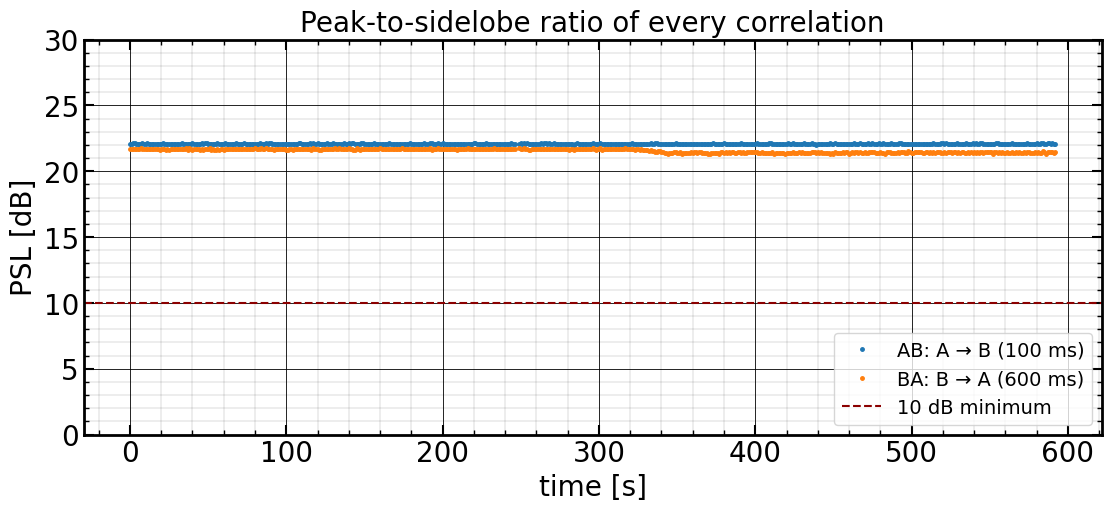

In [6]:
print(f"paired seconds: {len(resA)} (A ran {len(locA)} s, B {len(locB)} s; B started 3 s after A)")
print(f"valid: {np.isfinite(theta).sum()}, slot errors: "
      f"{sum('error' in l['slots'][s] for l in locA + locB for s in l['slots'])}")
for name, p, ph in (("AB (A -> B)", psl_ab, ph_ab), ("BA (B -> A)", psl_ba, ph_ba)):
    print(f"{name}: PSL min {p.min():.1f}, mean {p.mean():.1f} dB; carrier phase {ph.mean():+.3f} rad, sd {ph.std(ddof=1) * 1e3:.0f} mrad")
dieA = np.array([l["die_c"] for l in locA]); dieB = np.array([l["die_c"] for l in locB])
print(f"die temperature: A {dieA.min():.1f}-{dieA.max():.1f} C, B {dieB.min():.1f}-{dieB.max():.1f} C")

fig, ax = plt.subplots(1, 1, figsize=(11, 5), layout='constrained')
ax.plot(t, psl_ab, ".", ms=5, color="tab:blue", label="AB: A → B (100 ms)")
ax.plot(t, psl_ba, ".", ms=5, color="tab:orange", label="BA: B → A (600 ms)")
ax.axhline(10, color="darkred", ls="--", lw=1.5, label="10 dB minimum")
ax.set_ylim(0, 30); ax.set_xlabel("time [s]"); ax.set_ylabel("PSL [dB]")
ax.set_title("Peak-to-sidelobe ratio of every correlation", fontsize=20)
ax.legend(fontsize=14, loc="lower right"); grids(ax)
fig.savefig(FIG / "psl.png", dpi=150); plt.show()

## 4. The two one-way measurements

Each direction as a deviation from its own mean. The directions are different hardware (AB: A's DAC, the AB cable, B's ADC; BA: B's DAC, the BA cable, A's ADC), so their means differ by the non-reciprocity.

m_AB: mean 291.9446 ns, sdev  1.52 ps, second-to-second 1.47 ps, trend -0.04 ps/min, range 9.2 ps
m_BA: mean 293.0872 ns, sdev 24.57 ps, second-to-second 2.26 ps, trend -7.65 ps/min, range 68.2 ps
correlation between m_AB and m_BA of the same second: +0.06


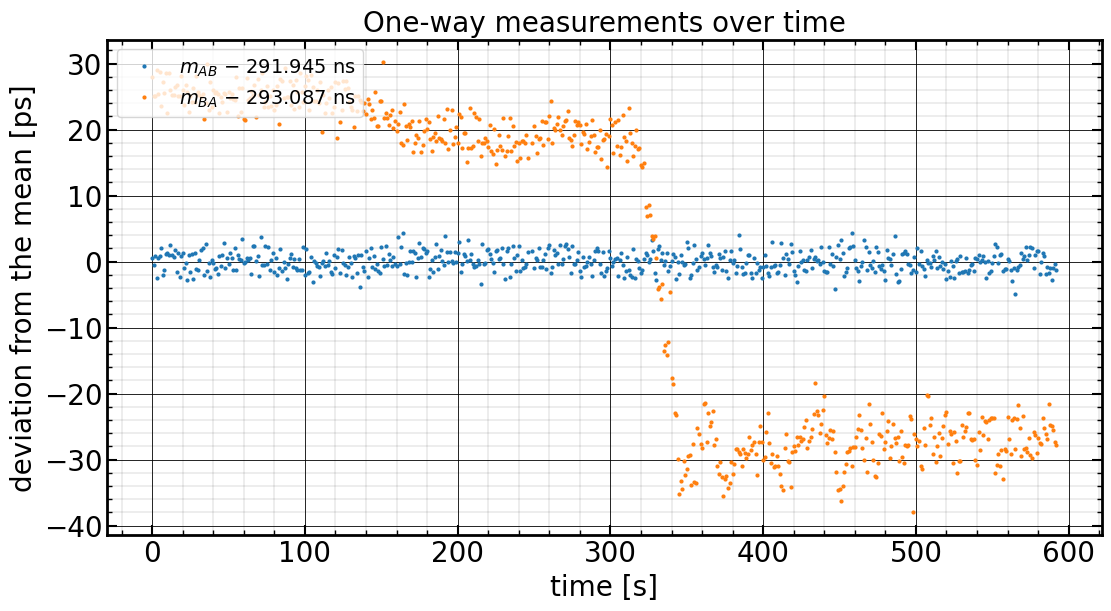

In [7]:
def trend(x):
    return np.polyfit(t, x, 1)[0] * 60
for name, m in (("m_AB", m_ab), ("m_BA", m_ba)):
    print(f"{name}: mean {m.mean():.4f} ns, sdev {m.std(ddof=1) * 1e3:5.2f} ps, "
          f"second-to-second {np.diff(m).std(ddof=1) / np.sqrt(2) * 1e3:4.2f} ps, "
          f"trend {trend(m) * 1e3:+.2f} ps/min, range {np.ptp(m) * 1e3:.1f} ps")
print(f"correlation between m_AB and m_BA of the same second: {np.corrcoef(m_ab, m_ba)[0, 1]:+.2f}")

fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
ax.plot(t, (m_ab - m_ab.mean()) * 1e3, ".", ms=4, color="tab:blue", label=f"$m_{{AB}}$ − {m_ab.mean():.3f} ns")
ax.plot(t, (m_ba - m_ba.mean()) * 1e3, ".", ms=4, color="tab:orange", label=f"$m_{{BA}}$ − {m_ba.mean():.3f} ns")
ax.set_xlabel("time [s]"); ax.set_ylabel("deviation from the mean [ps]")
ax.set_title("One-way measurements over time", fontsize=20)
ax.legend(fontsize=14, loc="upper left"); grids(ax)
fig.savefig(FIG / "one_way.png", dpi=150); plt.show()

## 5. The clock offset θ

$\theta = (m_{AB} - m_{BA})/2$, the zero-baseline constant. Shown over time with a 30-s running mean, then per minute, then as a histogram.

theta: mean -0.57128 ns (-571.3 ps), sdev 12.26 ps, second-to-second 1.42 ps, range 35.5 ps


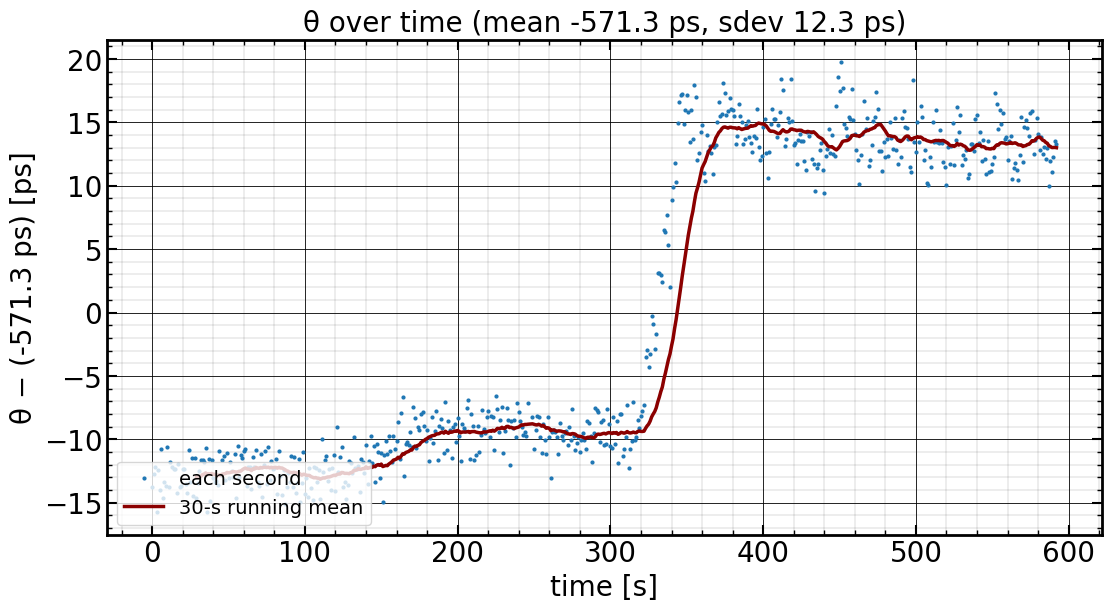

per minute:
    0- 60 s: theta  -12.67 ps (sdev 1.30), m_AB  +0.10, m_BA +25.45 ps
   60-120 s: theta  -12.67 ps (sdev 1.30), m_AB  -0.18, m_BA +25.16 ps
  120-180 s: theta  -11.02 ps (sdev 1.87), m_AB  +0.17, m_BA +22.21 ps
  180-240 s: theta   -9.23 ps (sdev 1.40), m_AB  +0.41, m_BA +18.87 ps
  240-300 s: theta   -9.50 ps (sdev 1.16), m_AB  +0.24, m_BA +19.25 ps
  300-360 s: theta   +2.30 ps (sdev 10.43), m_AB  -0.07, m_BA  -4.68 ps
  360-420 s: theta  +14.51 ps (sdev 1.80), m_AB  -0.20, m_BA -29.23 ps
  420-480 s: theta  +13.70 ps (sdev 2.15), m_AB  +0.06, m_BA -27.34 ps
  480-540 s: theta  +13.34 ps (sdev 1.75), m_AB  -0.37, m_BA -27.05 ps
  540-600 s: theta  +13.22 ps (sdev 1.72), m_AB  -0.20, m_BA -26.64 ps


In [8]:
th_ps = theta * 1e3
th_mean, th_sd = th_ps.mean(), th_ps.std(ddof=1)
print(f"theta: mean {theta.mean():+.5f} ns ({th_mean:+.1f} ps), sdev {th_sd:.2f} ps, "
      f"second-to-second {np.diff(th_ps).std(ddof=1) / np.sqrt(2):.2f} ps, range {np.ptp(th_ps):.1f} ps")

fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
ax.plot(t, th_ps - th_mean, ".", ms=4, color="tab:blue", label="each second")
ax.plot(t[29:], np.convolve(th_ps - th_mean, np.ones(30) / 30, mode="valid"), "-", color="darkred", lw=2.5,
        label="30-s running mean")
ax.set_xlabel("time [s]"); ax.set_ylabel(f"θ − ({th_mean:+.1f} ps) [ps]")
ax.set_title(f"θ over time (mean {th_mean:+.1f} ps, sdev {th_sd:.1f} ps)", fontsize=20)
ax.legend(fontsize=14, loc="lower left"); grids(ax)
fig.savefig(FIG / "theta_time.png", dpi=150); plt.show()

print("per minute:")
for k in range(0, len(th_ps), 60):
    s = slice(k, k + 60)
    print(f"  {k:3d}-{k + 60:3d} s: theta {th_ps[s].mean() - th_mean:+7.2f} ps (sdev {th_ps[s].std(ddof=1):4.2f}), "
          f"m_AB {(m_ab[s].mean() - m_ab.mean()) * 1e3:+6.2f}, m_BA {(m_ba[s].mean() - m_ba.mean()) * 1e3:+6.2f} ps")

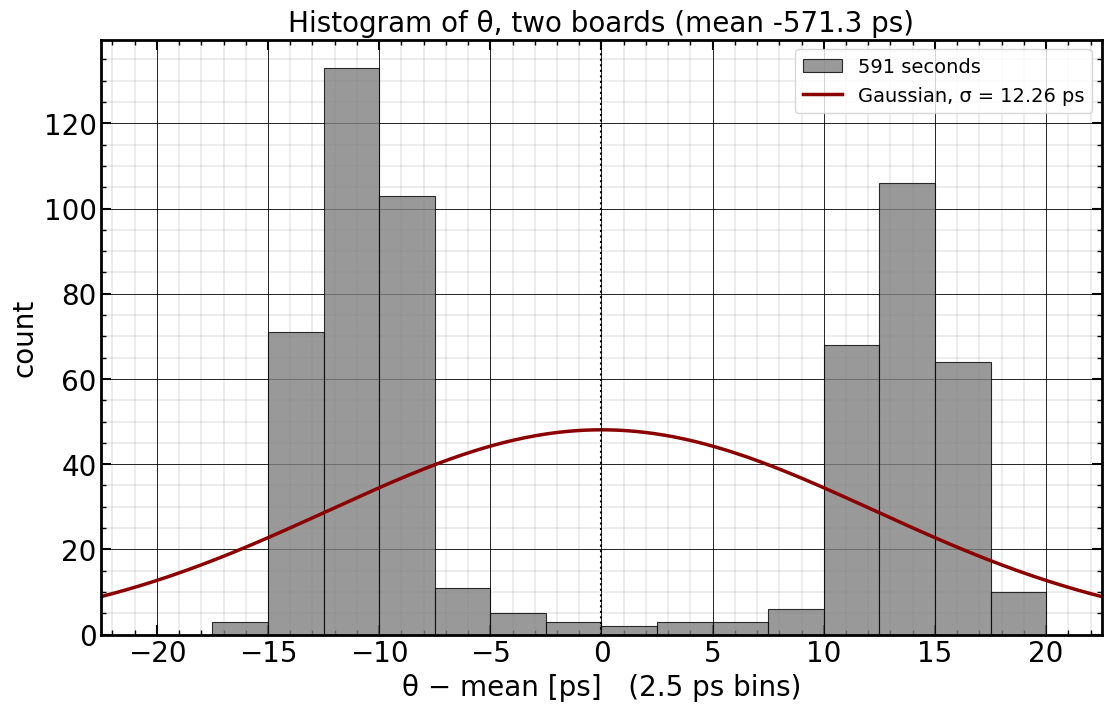

Shapiro-Wilk p = 5.7e-27 (not a Gaussian: the B -> A step and drift (section 9) widen the distribution)


In [9]:
BIN_PS = 2.5
dev = th_ps - th_mean
edge = BIN_PS * np.ceil(np.abs(dev).max() / BIN_PS + 1)
bins = np.arange(-edge, edge + BIN_PS / 2, BIN_PS)
x = np.linspace(bins[0], bins[-1], 400)
fig, ax = plt.subplots(1, 1, figsize=(11, 7), layout='constrained')
ax.hist(dev, bins=bins, color="grey", edgecolor="k", lw=0.8, alpha=0.8, label=f"{dev.size} seconds")
ax.plot(x, dev.size * BIN_PS * stats.norm.pdf(x, 0, th_sd), "-", color="darkred", lw=2.5,
        label=f"Gaussian, σ = {th_sd:.2f} ps")
ax.axvline(0, color="k", ls=":", lw=1.5)
ax.set_xlim(bins[0], bins[-1])
ax.set_xlabel(f"θ − mean [ps]   ({BIN_PS} ps bins)"); ax.set_ylabel("count")
ax.set_title(f"Histogram of θ, two boards (mean {th_mean:+.1f} ps)", fontsize=20)
ax.legend(fontsize=14, loc="upper right"); grids(ax)
fig.savefig(FIG / "theta_histogram.png", dpi=150); plt.show()
pv = stats.shapiro(dev).pvalue
print(f"Shapiro-Wilk p = {pv:.2g} ({'consistent with' if pv > 0.05 else 'not'} a Gaussian"
      f"{'' if pv > 0.05 else ': the B -> A step and drift (section 9) widen the distribution'})")

### Worked example: one value of θ from the raw data

This follows one second from the two boards' logs and the window B actually recorded to the logged θ, in four steps.

**Which second.** Each board counts its PPS from its own start (A started first, so A's count is higher; the offset is printed below), and the two boards' records are paired by their NTP time. Each board also saved the window it received every 60 s, at *its own* counts 6, 66, 126, … . Because of the count offset no paired second has both raw windows, so the example uses a second for which **B's raw window of the A → B burst is saved**. For B → A the example uses the peak that A logged for that second, and checks A's own saved window with the same count number (a few seconds earlier) to show the logged peaks come from the same calculation.

In [10]:
import importlib.util, sys
spec = importlib.util.spec_from_file_location(
    "correlator", "rf_clock_board/reference/rf_clock_v1.3.0.8/src/rf_clock/correlator.py")
correlator = importlib.util.module_from_spec(spec); sys.modules["correlator"] = correlator
spec.loader.exec_module(correlator)
ref = np.load("rf_clock_board/logs/m3_capture_20261027_232357.npz")["ref"]   # the transmitted PRN burst

def saved(rx_dir, slot):
    files = sorted(rx_dir.glob(f"{slot}_*.npy"), key=lambda p: int(p.stem.split("_")[1]))
    return [(int(f.stem.split("_")[1]), np.load(f).astype(np.complex128)) for f in files]

capAB = saved(DIR / f"rx_B_{RUN}", "AB"); capBA = saved(DIR / f"rx_A_{RUN}", "BA")

OFF = resA[0]["count_a"] - resA[0]["count_b"]          # A's count minus B's for the same second
cB = sorted(dict(capAB))[2]                               # a saved window of B (the third one)
rE = next(r for r in resA if r["count_b"] == cB)
eA, eB = byA[rE["count_a"]], byB[rE["count_b"]]
print(f"A's count is {OFF} above B's. Paired second: A count {rE['count_a']}, B count {rE['count_b']}; "
      f"NTP times of the two records differ by {abs(eA['t_sys'] - eB['t_sys']) * 1e3:.0f} ms\n")
print("                      node A (AB)          node B (72A)")
print(f"PPS tick             {eA['pps_tick']:>14d}       {eB['pps_tick']:>14d}   (100 MHz ticks since each board started)")
print(f"slot AB  TX / window  A TX  PPS+{eA['slots']['AB']['tx'] - eA['pps_tick']:<10d}  B window PPS+{eB['slots']['AB']['rx']['tick'] - eB['pps_tick']}")
print(f"slot BA  window / TX  A window PPS+{eA['slots']['BA']['rx']['tick'] - eA['pps_tick']:<9d} B TX  PPS+{eB['slots']['BA']['tx'] - eB['pps_tick']}")

A's count is 7 above B's. Paired second: A count 133, B count 126; NTP times of the two records differ by 2 ms

                      node A (AB)          node B (72A)
PPS tick                13200507679          12569681370   (100 MHz ticks since each board started)
slot AB  TX / window  A TX  PPS+10000000    B window PPS+9999875
slot BA  window / TX  A window PPS+59999875  B TX  PPS+60000000


**Step 1: when each burst is sent and when each window opens.** Every board measures time in its own 100 MHz ticks (10 ns), counted from the tick at which its own PPS arrived. In slot AB, A transmits at PPS + 10 000 000 ticks (100 ms) and B opens its receive window 125 ticks (1.25 µs) earlier by its own clock, so the burst falls inside the window. Slot BA is the same at PPS + 60 000 000 ticks, with B transmitting and A receiving. The large absolute tick numbers above cancel: only the positions relative to each board's own PPS enter.

**Step 2: where in the window the burst is (correlation).** The received window $r[n]$ (800 MS/s complex, 1.25 ns per sample) is cross-correlated with the transmitted burst $s[n]$:

$$c[k] = \sum_n r[n+k]\, s^*[n],$$

and the burst starts at the lag $k_0$ where $|c|$ peaks. The sample with the largest $|c|$ gives $k_0$ to 1.25 ns; a parabola through that sample and its two neighbours ($L$, $C$, $R$) refines it:

$$k_0 = k_{\max} + \frac{1}{2}\,\frac{L - R}{L - 2C + R}.$$

In [11]:
rx_ab = dict(capAB)[cB]                       # the window B recorded in slot AB of this second
c_ab = correlator.correlate(rx_ab, ref); mag = np.abs(c_ab)
k = int(np.argmax(mag)); L, C, R = mag[k - 1], mag[k], mag[k + 1]
k0 = k + 0.5 * (L - R) / (L - 2 * C + R)
print(f"window: {rx_ab.size} samples ({rx_ab.size * 1.25:.0f} ns); burst: {ref.size} samples")
print(f"largest |c| at k = {k}:  L = {L:.4g}, C = {C:.4g}, R = {R:.4g}")
print(f"k0 = {k} + 0.5 x ({L:.4g} - {R:.4g}) / ({L:.4g} - 2 x {C:.4g} + {R:.4g}) = {k0:.4f} samples")
print(f"logged by B for this second:  {eB['slots']['AB']['rx']['peak']:.4f} samples  "
      f"(PSL {correlator.find_peak(c_ab).peak_to_sidelobe_db:.1f} dB)")

window: 43848 samples (54810 ns); burst: 32841 samples
largest |c| at k = 1234:  L = 5.463e+10, C = 5.478e+10, R = 5.215e+10
k0 = 1234 + 0.5 x (5.463e+10 - 5.215e+10) / (5.463e+10 - 2 x 5.478e+10 + 5.215e+10) = 1233.5549 samples
logged by B for this second:  1233.5549 samples  (PSL 22.1 dB)


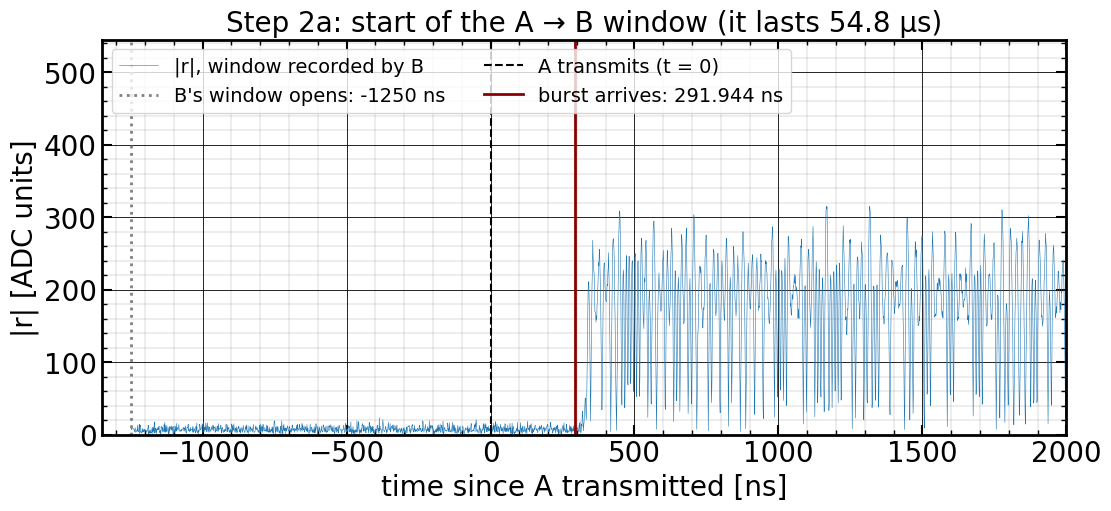

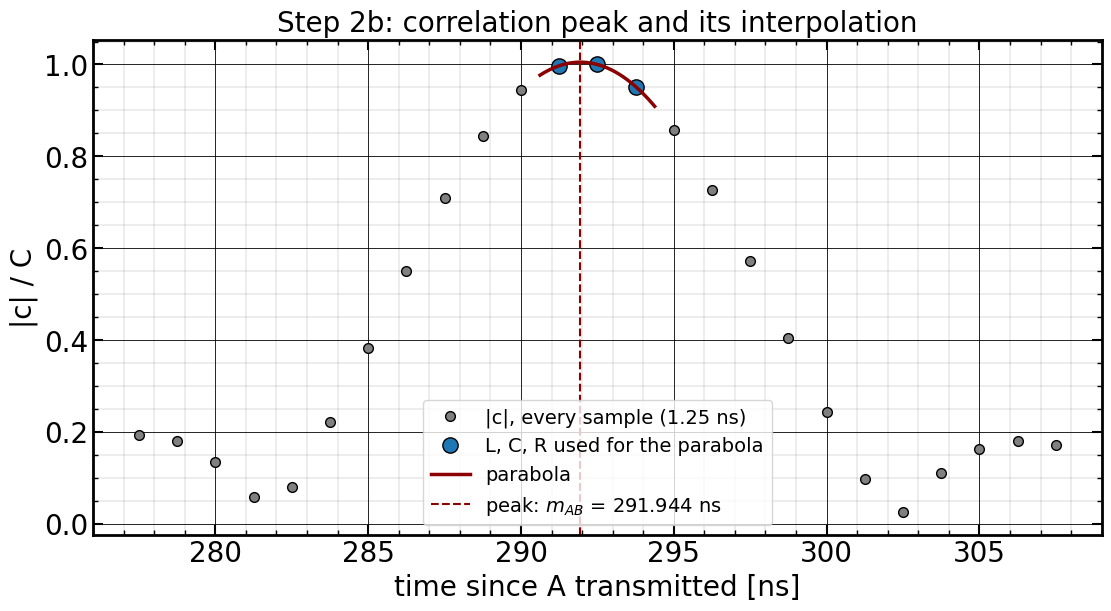

In [12]:
tx_ab = eA["slots"]["AB"]["tx"] - eA["pps_tick"]; win_ab = eB["slots"]["AB"]["rx"]["tick"] - eB["pps_tick"]
t_win = (win_ab - tx_ab) * 10.0                # window start, ns after A transmitted (by the two PPS)
tt = t_win + np.arange(rx_ab.size) * 1.25
fig, ax = plt.subplots(1, 1, figsize=(11, 5), layout='constrained')
ax.plot(tt, np.abs(rx_ab), lw=0.4, color="tab:blue", label="|r|, window recorded by B")
ax.axvline(t_win, color="grey", ls=":", lw=2, label=f"B's window opens: {t_win:.0f} ns")
ax.axvline(0, color="k", ls="--", lw=1.5, label="A transmits (t = 0)")
ax.axvline(t_win + k0 * 1.25, color="darkred", lw=2, label=f"burst arrives: {t_win + k0 * 1.25:.3f} ns")
ax.set_xlim(t_win - 100, 2000); ax.set_ylim(0, 1.6 * np.abs(rx_ab).max())
ax.set_xlabel("time since A transmitted [ns]"); ax.set_ylabel("|r| [ADC units]")
ax.set_title(f"Step 2a: start of the A → B window (it lasts {rx_ab.size * 1.25 / 1e3:.1f} µs)", fontsize=20)
ax.legend(fontsize=14, loc="upper left", ncol=2); grids(ax)
fig.savefig(FIG / "example_window_AB.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
w = np.arange(k - 12, k + 13)
ax.plot(t_win + w * 1.25, mag[w] / C, "o", ms=7, color="grey", mec="k", label="|c|, every sample (1.25 ns)")
ax.plot(t_win + np.array([k - 1, k, k + 1]) * 1.25, np.array([L, C, R]) / C, "o", ms=11, color="tab:blue",
        mec="k", label="L, C, R used for the parabola")
xs = np.linspace(k - 1.5, k + 1.5, 200)
a2 = (L - 2 * C + R) / 2; a1 = (R - L) / 2
ax.plot(t_win + xs * 1.25, (C + a1 * (xs - k) + a2 * (xs - k) ** 2) / C, "-", color="darkred", lw=2.5, label="parabola")
ax.axvline(t_win + k0 * 1.25, color="darkred", ls="--", lw=1.5, label=f"peak: $m_{{AB}}$ = {t_win + k0 * 1.25:.3f} ns")
ax.set_xlabel("time since A transmitted [ns]"); ax.set_ylabel("|c| / C")
ax.set_title("Step 2b: correlation peak and its interpolation", fontsize=20)
ax.legend(fontsize=14, loc="lower center"); grids(ax)
fig.savefig(FIG / "example_peak_AB.png", dpi=150); plt.show()

**Step 3: the two one-way measurements.** The time from transmission to arrival, each end on its own clock:

$$m = \big[(\text{window tick} - \text{PPS}_{\text{receiver}}) - (\text{TX tick} - \text{PPS}_{\text{transmitter}})\big] \times 10\ \text{ns} + k_0 \times 1.25\ \text{ns}.$$

The first term is the window's start relative to the transmission (−125 ticks = −1250 ns); the second is how far into the window the burst arrived.

In [13]:
m_ab_e = t_win + k0 * 1.25
tx_ba = eB["slots"]["BA"]["tx"] - eB["pps_tick"]; win_ba = eA["slots"]["BA"]["rx"]["tick"] - eA["pps_tick"]
k0_ba = eA["slots"]["BA"]["rx"]["peak"]
m_ba_e = (win_ba - tx_ba) * 10.0 + k0_ba * 1.25
print(f"m_AB = ({win_ab} - {tx_ab}) x 10 ns + {k0:.4f} x 1.25 ns = {m_ab_e:.4f} ns   (logged {rE['m_ab_ns']:.4f} ns)")
print(f"m_BA = ({win_ba} - {tx_ba}) x 10 ns + {k0_ba:.4f} x 1.25 ns = {m_ba_e:.4f} ns   (logged {rE['m_ba_ns']:.4f} ns)")
pB = correlator.estimate_delay(dict(capBA)[cB], ref)
print(f"\ncheck of the BA peak calculation on A's own saved window (A count {cB}, {OFF} s earlier): "
      f"recomputed {pB.index:.4f}, logged {byA[cB]['slots']['BA']['rx']['peak']:.4f} samples")

m_AB = (9999875 - 10000000) x 10 ns + 1233.5549 x 1.25 ns = 291.9436 ns   (logged 291.9436 ns)
m_BA = (59999875 - 60000000) x 10 ns + 1234.4914 x 1.25 ns = 293.1143 ns   (logged 293.1143 ns)

check of the BA peak calculation on A's own saved window (A count 126, 7 s earlier): recomputed 1234.4878, logged 1234.4878 samples


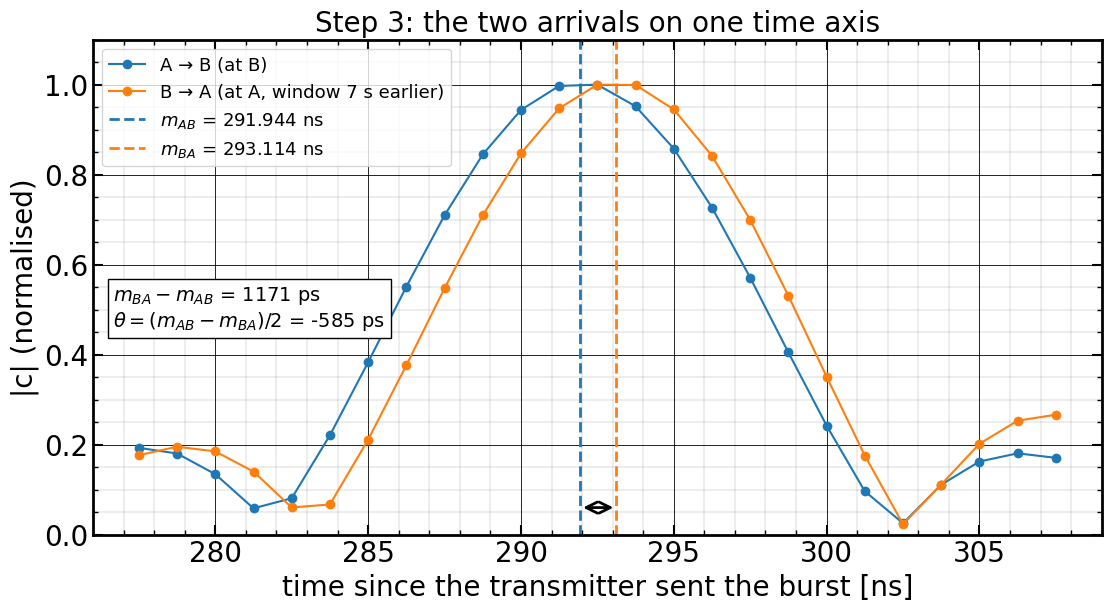

In [14]:
rx_ba = dict(capBA)[cB]; c_ba = np.abs(correlator.correlate(rx_ba, ref))
fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
for lab, cm, t_w, kk, col in (("A → B (at B)", mag, t_win, k0, "tab:blue"),
                               (f"B → A (at A, window {OFF} s earlier)", c_ba, (win_ba - tx_ba) * 10.0, pB.index, "tab:orange")):
    j = int(round(kk)); w = np.arange(j - 12, j + 13)
    ax.plot(t_w + w * 1.25, cm[w] / cm[j], "o-", ms=6, lw=1.5, color=col, label=lab)
ax.axvline(m_ab_e, color="tab:blue", ls="--", lw=2, label=f"$m_{{AB}}$ = {m_ab_e:.3f} ns")
ax.axvline(m_ba_e, color="tab:orange", ls="--", lw=2, label=f"$m_{{BA}}$ = {m_ba_e:.3f} ns")
ax.annotate("", xy=(m_ba_e, 0.06), xytext=(m_ab_e, 0.06), arrowprops=dict(arrowstyle="<->", lw=2))
ax.text(0.02, 0.42, f"$m_{{BA}} - m_{{AB}}$ = {(m_ba_e - m_ab_e) * 1e3:.0f} ps\n$\\theta = (m_{{AB}} - m_{{BA}})/2$ = {(m_ab_e - m_ba_e) / 2 * 1e3:.0f} ps",
        ha="left", transform=ax.transAxes, fontsize=14, bbox=dict(facecolor="white", edgecolor="k"))
ax.set_xlabel("time since the transmitter sent the burst [ns]"); ax.set_ylabel("|c| (normalised)")
ax.set_ylim(0, 1.1)
ax.set_title("Step 3: the two arrivals on one time axis", fontsize=20)
ax.legend(fontsize=13, loc="upper left"); grids(ax)
fig.savefig(FIG / "example_two_arrivals.png", dpi=150); plt.show()

**Step 4: θ and the one-way delay.** Write $d_{AB}$, $d_{BA}$ for the true propagation times (cables, filters, attenuators and the converter paths of both boards) and $t_A$, $t_B$ for the true times of the two boards' PPS ticks. A's burst leaves at $t_A$ + 100 ms and arrives at $t_A$ + 100 ms + $d_{AB}$; B measures that arrival from $t_B$, so

$$m_{AB} = d_{AB} + (t_A - t_B), \qquad m_{BA} = d_{BA} - (t_A - t_B).$$

Half the difference and half the sum separate the clocks from the path:

$$\theta = \frac{m_{AB} - m_{BA}}{2} = (t_A - t_B) + \frac{d_{AB} - d_{BA}}{2}, \qquad \text{delay} = \frac{m_{AB} + m_{BA}}{2} = \frac{d_{AB} + d_{BA}}{2}.$$

A clock offset changes the two directions in opposite ways and moves θ one for one. A delay common to both directions (a longer shared cable, temperature) cancels in θ. A difference between the two directions, the non-reciprocity $\Delta = d_{AB} - d_{BA}$, enters θ as $\Delta/2$ and **cannot be told apart from a clock offset**. That is why a zero-baseline run like this one is needed: it measures the constant to subtract.

In [15]:
th_e = (m_ab_e - m_ba_e) / 2; dl_e = (m_ab_e + m_ba_e) / 2
print(f"theta = ({m_ab_e:.4f} - {m_ba_e:.4f}) / 2 = {th_e * 1e3:+.2f} ps   (logged {rE['theta_ns'] * 1e3:+.2f} ps; "
      f"run mean {th_mean:+.1f} ps)")
print(f"delay = ({m_ab_e:.4f} + {m_ba_e:.4f}) / 2 = {dl_e:.4f} ns   (logged {rE['delay_ns']:.4f} ns)\n")
print("What each kind of change would do to this second (illustration):")
print("                                            m_AB [ns]   m_BA [ns]   theta [ps]   delay [ns]")
for lab, dab, dba, off in (("as measured", 0, 0, 0),
                           ("B's clock 1 ns early (t_A - t_B = +1 ns)", 0, 0, 1),
                           ("both paths 1 ns longer", 1, 1, 0),
                           ("A->B path alone 1 ns longer (Delta)", 1, 0, 0)):
    a, b = m_ab_e + dab + off, m_ba_e + dba - off
    print(f"  {lab:42s} {a:10.4f}  {b:10.4f}   {(a - b) / 2 * 1e3:+9.2f}   {(a + b) / 2:9.4f}")

theta = (291.9436 - 293.1143) / 2 = -585.36 ps   (logged -585.36 ps; run mean -571.3 ps)
delay = (291.9436 + 293.1143) / 2 = 292.5289 ns   (logged 292.5289 ns)

What each kind of change would do to this second (illustration):
                                            m_AB [ns]   m_BA [ns]   theta [ps]   delay [ns]
  as measured                                  291.9436    293.1143     -585.36    292.5289
  B's clock 1 ns early (t_A - t_B = +1 ns)     292.9436    292.1143     +414.64    292.5289
  both paths 1 ns longer                       292.9436    294.1143     -585.36    293.5289
  A->B path alone 1 ns longer (Delta)          292.9436    293.1143      -85.36    293.0289


## 6. The one-way delay

$(m_{AB} + m_{BA})/2$: cables, filters, attenuators and both boards' converter paths.

one-way delay: mean 292.5159 ns, sdev 12.36 ps, trend -3.85 ps/min


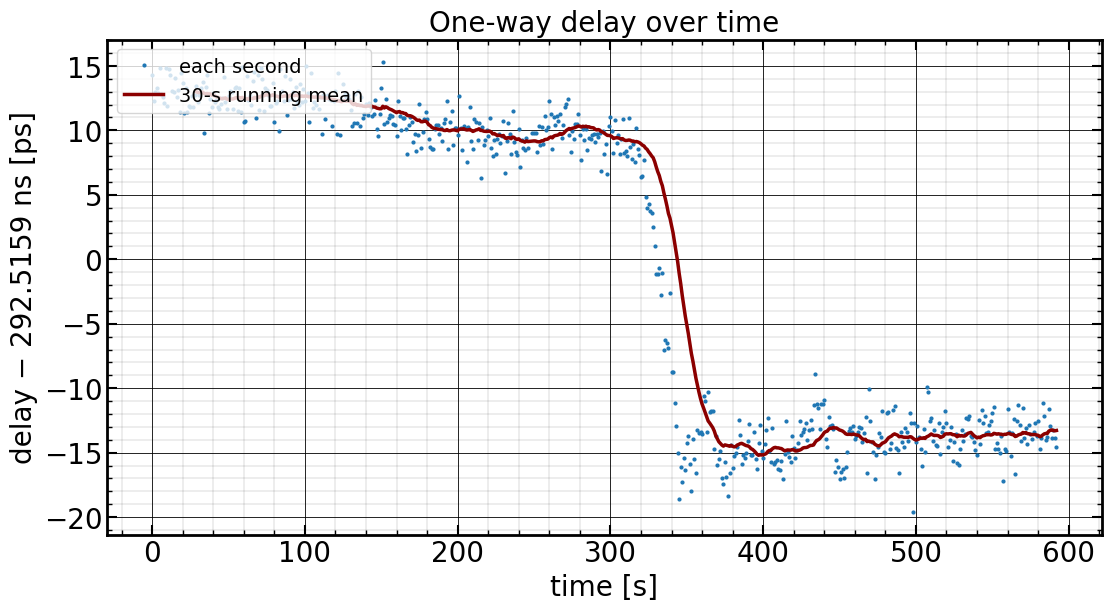

In [16]:
print(f"one-way delay: mean {delay.mean():.4f} ns, sdev {delay.std(ddof=1) * 1e3:.2f} ps, trend {trend(delay) * 1e3:+.2f} ps/min")
fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
ax.plot(t, (delay - delay.mean()) * 1e3, ".", ms=4, color="tab:blue", label="each second")
ax.plot(t[29:], np.convolve((delay - delay.mean()) * 1e3, np.ones(30) / 30, mode="valid"), "-", color="darkred",
        lw=2.5, label="30-s running mean")
ax.set_xlabel("time [s]"); ax.set_ylabel(f"delay − {delay.mean():.4f} ns [ps]")
ax.set_title("One-way delay over time", fontsize=20)
ax.legend(fontsize=14, loc="upper left"); grids(ax)
fig.savefig(FIG / "delay_time.png", dpi=150); plt.show()

## 7. Stability with averaging

Standard deviation of the mean of N consecutive seconds, and the overlapping Allan deviation of θ (θ taken as the time error between the two boards; see the self-test notebook for the definition).

N =   1: theta 12.26   m_AB  1.52   m_BA 24.57 ps
N =   2: theta 12.23   m_AB  1.11   m_BA 24.53 ps
N =   5: theta 12.23   m_AB  0.72   m_BA 24.55 ps
N =  10: theta 12.26   m_AB  0.53   m_BA 24.63 ps
N =  20: theta 12.33   m_AB  0.40   m_BA 24.77 ps
N =  30: theta 12.35   m_AB  0.36   m_BA 24.83 ps
N =  60: theta 12.17   m_AB  0.24   m_BA 24.49 ps


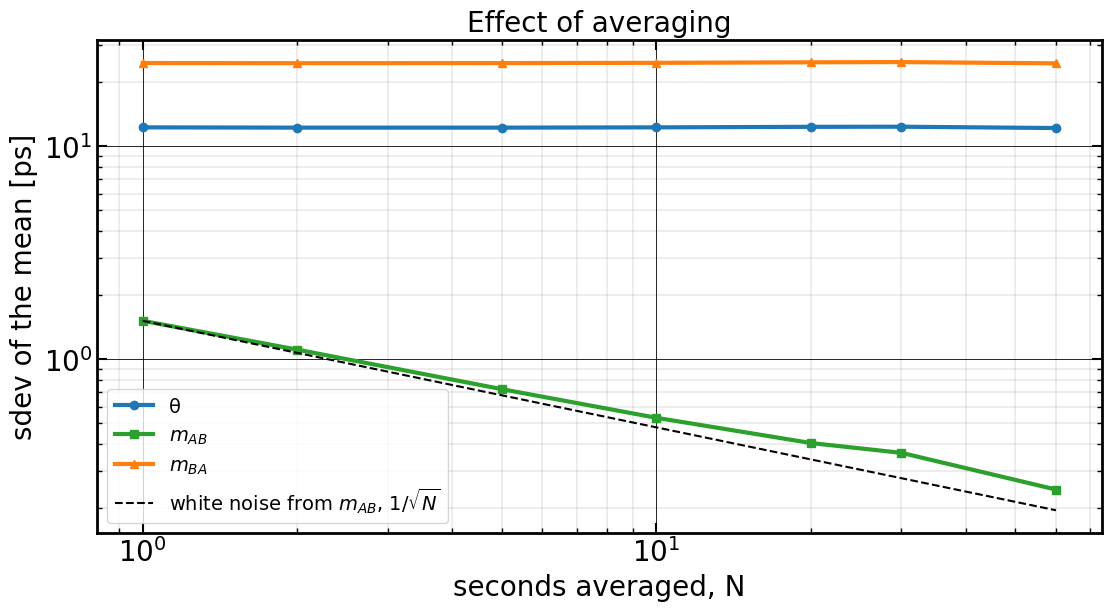

In [17]:
def sd_of_mean(y, Ns):
    out = []
    for n in Ns:
        k = y.size // n
        out.append(y[: k * n].reshape(k, n).mean(axis=1).std(ddof=1))
    return np.array(out)

def oadev(x_s, taus):
    return np.array([np.sqrt(np.mean((x_s[2 * m:] - 2 * x_s[m:-m] + x_s[:-2 * m]) ** 2) / (2 * m ** 2)) for m in taus])

Ns = np.array([1, 2, 5, 10, 20, 30, 60])
sd_th, sd_ab, sd_ba = sd_of_mean(th_ps, Ns), sd_of_mean(m_ab * 1e3, Ns), sd_of_mean(m_ba * 1e3, Ns)
for n, a, b, c in zip(Ns, sd_th, sd_ab, sd_ba):
    print(f"N = {n:3d}: theta {a:5.2f}   m_AB {b:5.2f}   m_BA {c:5.2f} ps")
fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
ax.loglog(Ns, sd_th, "o-", color="tab:blue", label="θ")
ax.loglog(Ns, sd_ab, "s-", color="tab:green", label="$m_{AB}$")
ax.loglog(Ns, sd_ba, "^-", color="tab:orange", label="$m_{BA}$")
ax.loglog(Ns, sd_ab[0] / np.sqrt(Ns), "k--", lw=1.5, label="white noise from $m_{AB}$, $1/\\sqrt{N}$")
ax.set_xlabel("seconds averaged, N"); ax.set_ylabel("sdev of the mean [ps]")
ax.set_title("Effect of averaging", fontsize=20)
ax.legend(fontsize=14); grids(ax)
fig.savefig(FIG / "averaging.png", dpi=150); plt.show()

tau =   1 s: ADEV 2.40e-12
tau =   2 s: ADEV 1.27e-12
tau =   3 s: ADEV 8.55e-13
tau =   4 s: ADEV 6.98e-13
tau =   7 s: ADEV 4.03e-13
tau =  11 s: ADEV 2.95e-13
tau =  18 s: ADEV 2.12e-13
tau =  29 s: ADEV 1.69e-13
tau =  47 s: ADEV 1.48e-13
tau =  75 s: ADEV 1.29e-13
tau = 122 s: ADEV 1.08e-13
tau = 197 s: ADEV 7.64e-14


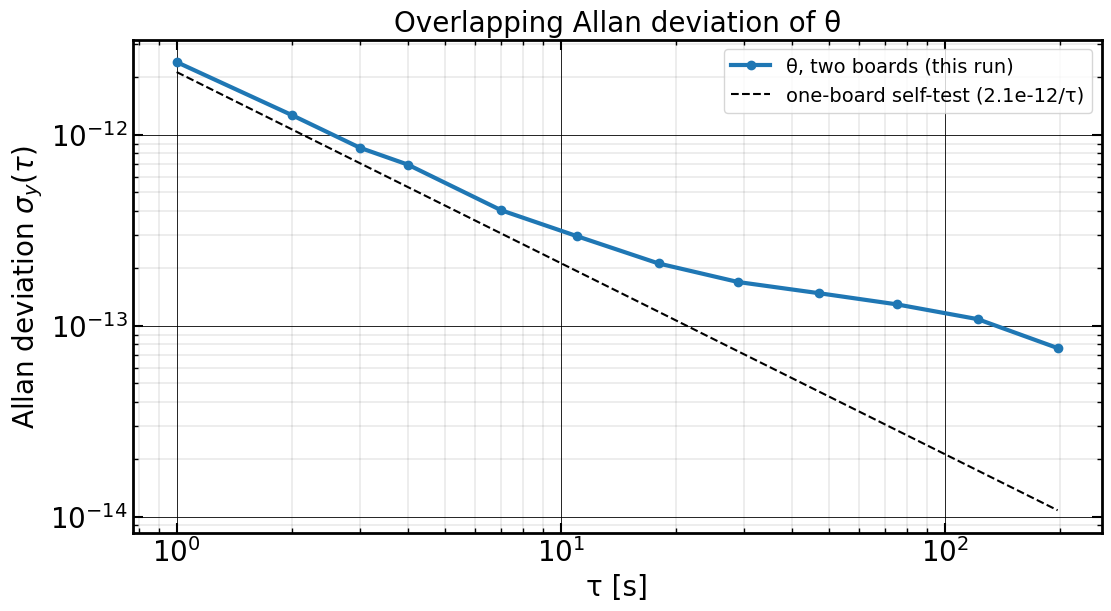

In [18]:
taus = np.unique(np.round(np.logspace(0, np.log10(th_ps.size // 3), 12)).astype(int))
ad = oadev(th_ps * 1e-12, taus)
for tau, v in zip(taus, ad):
    print(f"tau = {tau:3d} s: ADEV {v:.2e}")
ad_self = 2.13e-12 / taus                    # one-board self-test: 2.13e-12 at 1 s, falling as 1/tau
fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
ax.loglog(taus, ad, "o-", color="tab:blue", label="θ, two boards (this run)")
ax.loglog(taus, ad_self, "k--", lw=1.5, label="one-board self-test (2.1e-12/τ)")
ax.set_xlabel("τ [s]"); ax.set_ylabel("Allan deviation $\\sigma_y(\\tau)$")
ax.set_title("Overlapping Allan deviation of θ", fontsize=20)
ax.legend(fontsize=14); grids(ax)
fig.savefig(FIG / "allan.png", dpi=150); plt.show()

## 8. The saved captures: received levels of the two directions

Every 60 s each board kept the window it received (A: slot BA, B: slot AB), at its own counts (A's count is 7 above B's for the same second). The PRN reference is the same waveform and amplitude as in M3 (taken from the M3 capture file), and the correlator is the RF-clock source in this repository.

In [19]:
# correlator, reference burst and saved windows loaded in section 5 (worked example)
print("count  AB (A->B at B): rms   peak   PSL  |  BA (B->A at A): rms   peak   PSL")
for (ca, xa), (cb, xb) in zip(capAB, capBA):
    pa, pb = correlator.estimate_delay(xa, ref), correlator.estimate_delay(xb, ref)
    print(f"{ca:4d}/{cb:<4d}        {np.sqrt(np.mean(np.abs(xa) ** 2)):6.1f} {pa.index:8.3f} {pa.peak_to_sidelobe_db:5.1f}  |"
          f"        {np.sqrt(np.mean(np.abs(xb) ** 2)):6.1f} {pb.index:8.3f} {pb.peak_to_sidelobe_db:5.1f}")
def level(caps):            # median rms of the saved windows that contain the burst (PSL > 10 dB)
    return np.median([np.sqrt(np.mean(np.abs(x) ** 2)) for _, x in caps
                      if correlator.estimate_delay(x, ref).peak_to_sidelobe_db > 10])
lvl_ab, lvl_ba = level(capAB), level(capBA)
print(f"\nreceived level: AB {lvl_ab:.0f}, BA {lvl_ba:.0f} ADC units rms; BA relative to AB {20 * np.log10(lvl_ba / lvl_ab):+.1f} dB "
      f"(windows without a burst, PSL < 10 dB, left out)")

count  AB (A->B at B): rms   peak   PSL  |  BA (B->A at A): rms   peak   PSL
   6/6            163.9 1233.556  22.1  |           8.5 5881.347   0.7
  66/66           163.8 1233.555  22.1  |         108.5 1234.489  21.7
 126/126          163.8 1233.555  22.1  |         108.2 1234.488  21.7
 186/186          163.7 1233.557  22.1  |         107.4 1234.485  21.7
 246/246          163.6 1233.558  22.1  |         107.4 1234.485  21.7
 308/306          163.6 1233.556  22.1  |         107.4 1234.486  21.7
 368/366          163.7 1233.555  22.1  |          91.2 1234.443  21.3
 428/426          163.6 1233.553  22.1  |          92.3 1234.442  21.4
 488/486          163.6 1233.556  22.1  |          81.5 1234.444  21.4
 548/546          163.6 1233.556  22.1  |          81.5 1234.450  21.4



received level: AB 164, BA 107 ADC units rms; BA relative to AB -3.7 dB (windows without a burst, PSL < 10 dB, left out)


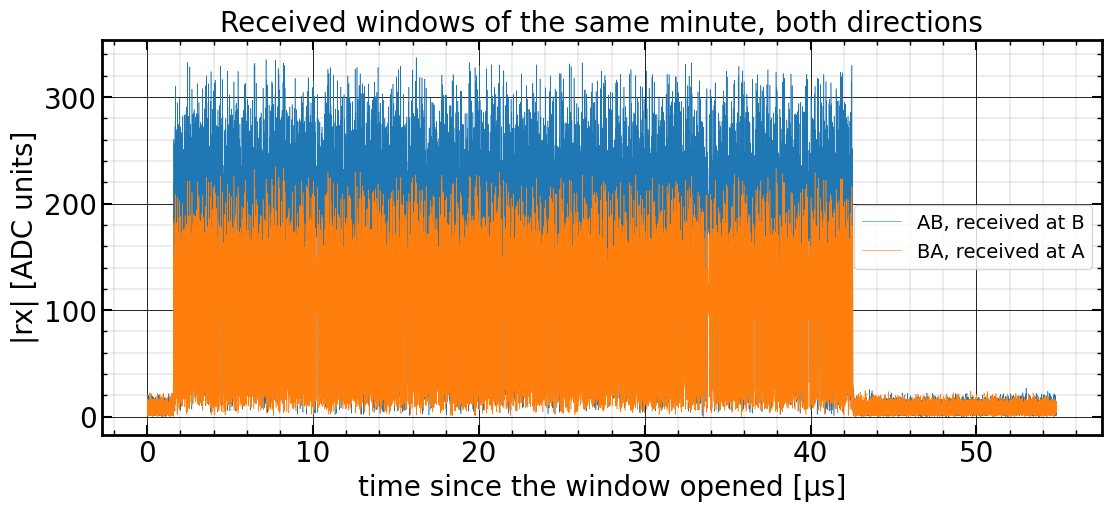

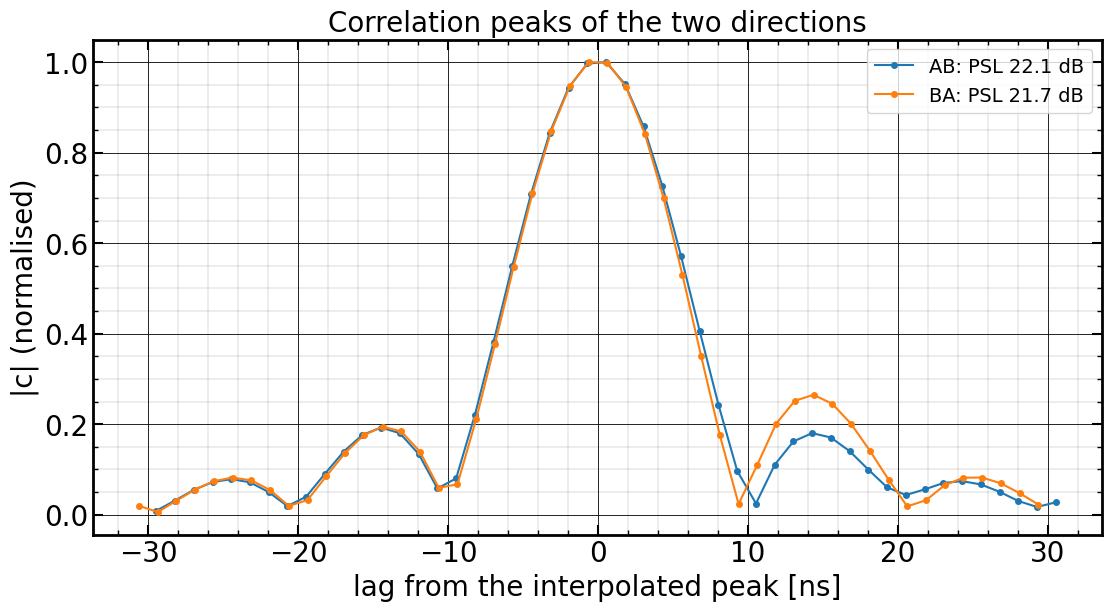

In [20]:
(_, xa), (_, xb) = capAB[3], capBA[3]
fig, ax = plt.subplots(1, 1, figsize=(11, 5), layout='constrained')
tt = np.arange(xa.size) / 800e6 * 1e6
ax.plot(tt, np.abs(xa), lw=0.4, color="tab:blue", label="AB, received at B")
ax.plot(tt, np.abs(xb), lw=0.4, color="tab:orange", label="BA, received at A")
ax.set_xlabel("time since the window opened [µs]"); ax.set_ylabel("|rx| [ADC units]")
ax.set_title("Received windows of the same minute, both directions", fontsize=20)
ax.legend(fontsize=14, loc="center right"); grids(ax)
fig.savefig(FIG / "captures.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
for (lab, x, col) in (("AB", xa, "tab:blue"), ("BA", xb, "tab:orange")):
    c = np.abs(correlator.correlate(x, ref)); p = correlator.find_peak(correlator.correlate(x, ref))
    k = p.integer_index; w = np.arange(k - 24, k + 25)
    ax.plot((w - p.index) * 1.25, c[w] / c[k], "o-", ms=4, lw=1.5, color=col, label=f"{lab}: PSL {p.peak_to_sidelobe_db:.1f} dB")
ax.set_xlabel("lag from the interpolated peak [ns]"); ax.set_ylabel("|c| (normalised)")
ax.set_title("Correlation peaks of the two directions", fontsize=20)
ax.legend(fontsize=14); grids(ax)
fig.savefig(FIG / "correlation_peaks.png", dpi=150); plt.show()

## 9. Before and after the attenuator fix

The previous run (`20261028_001010`, 27–28 October, 20 dB in B → A and 10 dB in A → B) analysed the same way, side by side with this one. Received levels come from each run's saved windows, per-second noise from the second-to-second differences, short-term noise of θ from θ minus its 61-s running mean.

In [21]:
PREV = "20261028_001010"; PDIR = Path("rf_clock_board/twtt_pair") / PREV
resP = [l for l in read(PDIR / f"twtt_A_{PREV}.jsonl") if l["type"] == "result"]
tP = np.array([r["t_sys"] - resP[0]["t_sys"] for r in resP])
m_ab_p = np.array([r["m_ab_ns"] for r in resP]); m_ba_p = np.array([r["m_ba_ns"] for r in resP])
th_p = (m_ab_p - m_ba_p) / 2 * 1e3
lvl_ab_p, lvl_ba_p = level(saved(PDIR / f"rx_B_{PREV}", "AB")), level(saved(PDIR / f"rx_A_{PREV}", "BA"))

s2s = lambda y: np.diff(y).std(ddof=1) / np.sqrt(2)
def resid(y, w=61):
    return y[w // 2: -(w // 2)] - np.convolve(y, np.ones(w) / w, mode="valid")
rows_ba = [
    ("attenuators A -> B / B -> A", "10 dB / 20 dB", "5 dB / 5 dB"),
    ("received level A -> B [ADC rms]", f"{lvl_ab_p:.0f}", f"{lvl_ab:.0f}"),
    ("received level B -> A [ADC rms]", f"{lvl_ba_p:.0f}", f"{lvl_ba:.0f}"),
    ("B -> A relative to A -> B [dB]", f"{20 * np.log10(lvl_ba_p / lvl_ab_p):+.1f}", f"{20 * np.log10(lvl_ba / lvl_ab):+.1f}"),
    ("m_AB per-second noise [ps]", f"{s2s(m_ab_p) * 1e3:.2f}", f"{s2s(m_ab) * 1e3:.2f}"),
    ("m_BA per-second noise [ps]", f"{s2s(m_ba_p) * 1e3:.2f}", f"{s2s(m_ba) * 1e3:.2f}"),
    ("m_BA range over the run [ps]", f"{np.ptp(m_ba_p) * 1e3:.1f}", f"{np.ptp(m_ba) * 1e3:.1f}"),
    ("theta mean [ps]", f"{th_p.mean():+.1f}", f"{th_mean:+.1f}"),
    ("theta sdev, whole run [ps]", f"{th_p.std(ddof=1):.2f}", f"{th_sd:.2f}"),
    ("theta per-second noise [ps]", f"{s2s(th_p):.2f}", f"{s2s(th_ps):.2f}"),
    ("theta short-term (minus 61-s mean) [ps]", f"{resid(th_p).std(ddof=1):.2f}", f"{resid(th_ps).std(ddof=1):.2f}"),
    ("theta ADEV at 1 s", f"{oadev(th_p * 1e-12, [1])[0]:.1e}", f"{ad[0]:.1e}"),
    ("one-way delay [ns]", f"{(m_ab_p + m_ba_p).mean() / 2:.4f}", f"{delay.mean():.4f}"),
]
print(f"{'':42s} {'before (27 Oct)':>16s} {'after (28 Oct)':>16s}")
for r in rows_ba:
    print(f"{r[0]:42s} {r[1]:>16s} {r[2]:>16s}")

                                            before (27 Oct)   after (28 Oct)
attenuators A -> B / B -> A                   10 dB / 20 dB      5 dB / 5 dB
received level A -> B [ADC rms]                         103              164
received level B -> A [ADC rms]                          29              107
B -> A relative to A -> B [dB]                        -10.9             -3.7
m_AB per-second noise [ps]                             1.93             1.47
m_BA per-second noise [ps]                             5.79             2.26
m_BA range over the run [ps]                           74.8             68.2
theta mean [ps]                                      -647.2           -571.3
theta sdev, whole run [ps]                             8.00            12.26
theta per-second noise [ps]                            3.09             1.42
theta short-term (minus 61-s mean) [ps]                3.25             2.15
theta ADEV at 1 s                                   5.3e-12          2.4e-12

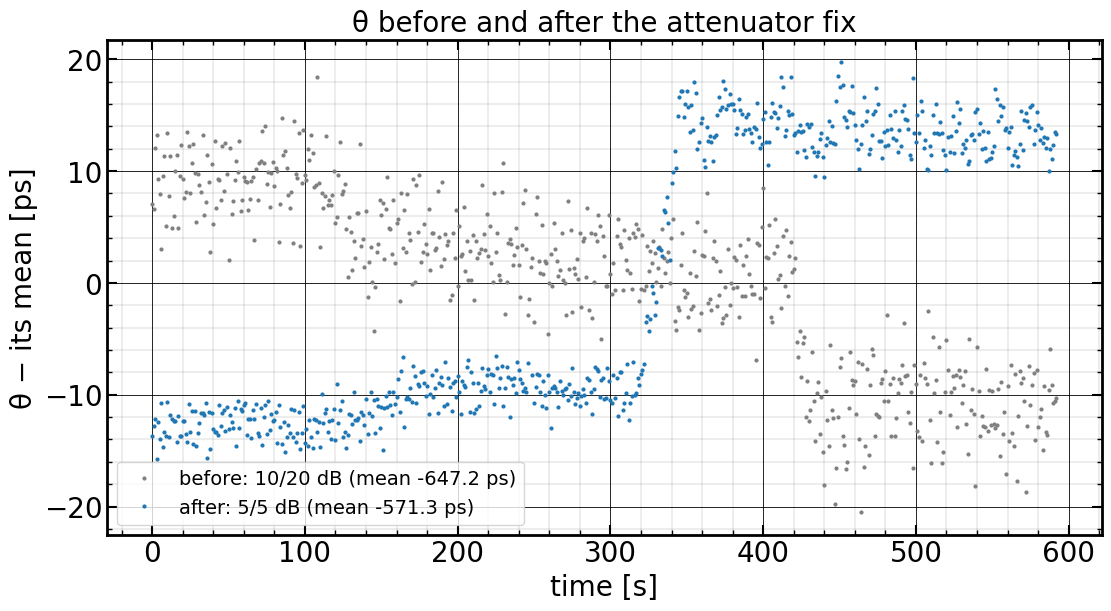

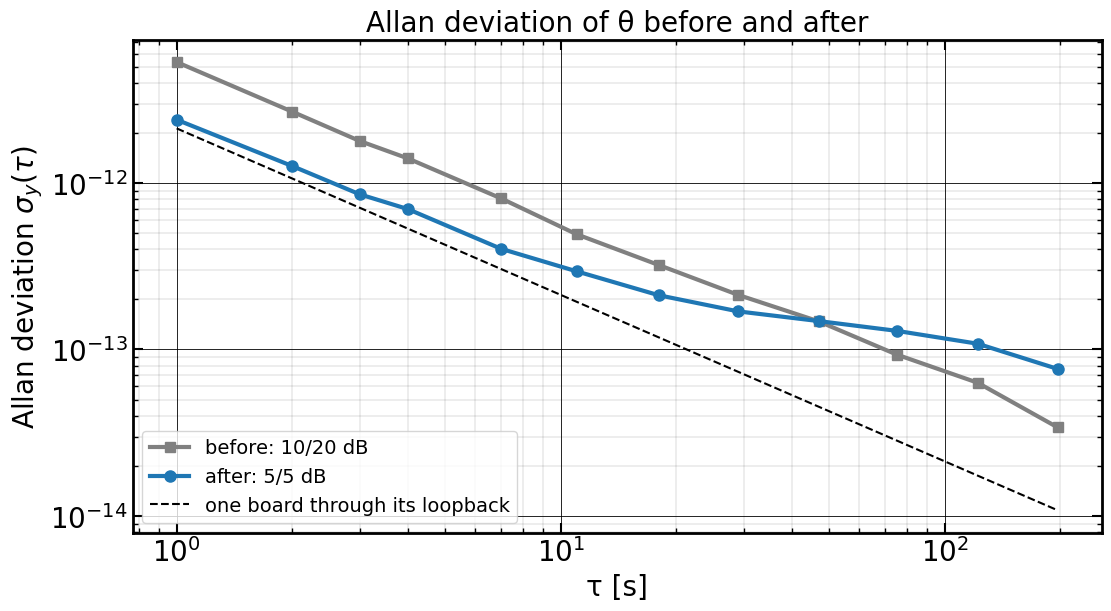

In [22]:
fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
ax.plot(tP, th_p - th_p.mean(), ".", ms=4, color="grey", label=f"before: 10/20 dB (mean {th_p.mean():+.1f} ps)")
ax.plot(t, th_ps - th_mean, ".", ms=4, color="tab:blue", label=f"after: 5/5 dB (mean {th_mean:+.1f} ps)")
ax.set_xlabel("time [s]"); ax.set_ylabel("θ − its mean [ps]")
ax.set_title("θ before and after the attenuator fix", fontsize=20)
ax.legend(fontsize=14, loc="lower left"); grids(ax)
fig.savefig(FIG / "before_after_theta.png", dpi=150); plt.show()

tausP = np.unique(np.round(np.logspace(0, np.log10(th_p.size // 3), 12)).astype(int))
adP = oadev(th_p * 1e-12, tausP)
fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
ax.loglog(tausP, adP, "s-", color="grey", ms=7, label="before: 10/20 dB")
ax.loglog(taus, ad, "o-", color="tab:blue", ms=8, label="after: 5/5 dB")
ax.loglog(taus, 2.13e-12 / taus, "k--", lw=1.5, label="one board through its loopback")
ax.set_xlabel("τ [s]"); ax.set_ylabel("Allan deviation $\\sigma_y(\\tau)$")
ax.set_title("Allan deviation of θ before and after", fontsize=20)
ax.legend(fontsize=14, loc="lower left"); grids(ax)
fig.savefig(FIG / "before_after_allan.png", dpi=150); plt.show()

### The B → A wander

After the fix B → A is still not stable: it drifts during the first five minutes and steps down between t ≈ 320 and 345 s, while A → B stays flat. As in the previous run, two checks: the received level of the saved windows (section 8), and the carrier phase. If the B → A path really became shorter by δ, the carrier phase at A would turn by +2π × 5.8 GHz × δ (+1.82 rad for 50 ps).

t = 340 s: m_BA -13.0 ps in one second, phase +0.115 rad
t = 498 s: m_BA -14.2 ps in one second, phase +0.042 rad
t = 499 s: m_BA +11.9 ps in one second, phase +0.023 rad
over the run: m_BA -51.7 ps, phase +0.81 rad (a real path change would give +1.88 rad); m_AB range 9.2 ps


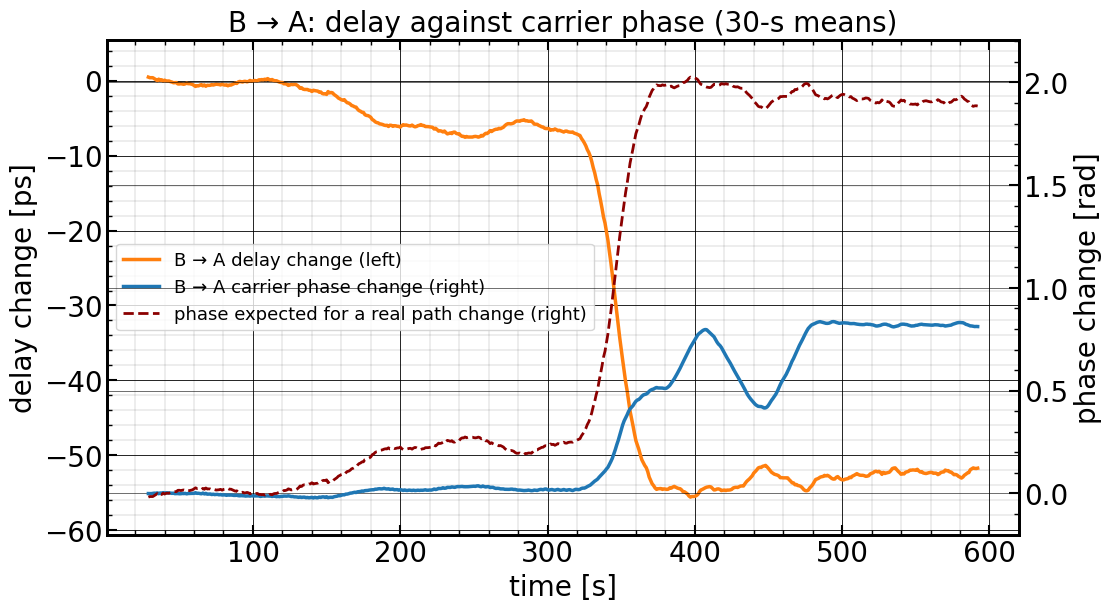

In [23]:
win = 30
sm = lambda y: np.convolve(y, np.ones(win) / win, mode="valid")
d_ba_ps = sm((m_ba - m_ba[:60].mean()) * 1e3)
d_ph = sm(np.unwrap(ph_ba) - np.unwrap(ph_ba)[:60].mean())
expected = -2 * np.pi * 5.8e9 * d_ba_ps * 1e-12
jumps = np.argsort(-np.abs(np.diff(m_ba)))[:3]
for k in sorted(jumps):
    print(f"t = {t[k + 1]:.0f} s: m_BA {np.diff(m_ba)[k] * 1e3:+.1f} ps in one second, phase {np.diff(np.unwrap(ph_ba))[k]:+.3f} rad")
print(f"over the run: m_BA {d_ba_ps[-1]:+.1f} ps, phase {d_ph[-1]:+.2f} rad (a real path change would give {expected[-1]:+.2f} rad); "
      f"m_AB range {np.ptp(m_ab) * 1e3:.1f} ps")
fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
ax2 = ax.twinx()
ax.plot(t[win - 1:], d_ba_ps, "-", color="tab:orange", lw=2.5, label="B → A delay change (left)")
ax2.plot(t[win - 1:], d_ph, "-", color="tab:blue", lw=2.5, label="B → A carrier phase change (right)")
ax2.plot(t[win - 1:], expected, "--", color="darkred", lw=2, label="phase expected for a real path change (right)")
ax.set_xlabel("time [s]"); ax.set_ylabel("delay change [ps]"); ax2.set_ylabel("phase change [rad]")
lo = min(d_ba_ps.min(), 0) - 5; hi = max(d_ba_ps.max(), 0) + 5
ax.set_ylim(lo, hi); ax2.set_ylim(-2 * np.pi * 5.8e9 * hi * 1e-12, -2 * np.pi * 5.8e9 * lo * 1e-12)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=13, loc="center left")
ax.set_title(f"B → A: delay against carrier phase ({win}-s means)", fontsize=20)
grids(ax); ax2.minorticks_on()
fig.savefig(FIG / "ba_phase_vs_delay.png", dpi=150); plt.show()

## 10. Comparison

In [24]:
rows = [
    ("One board (AB), loopback, 27 Oct, 300 s", "0 (truth)", "+0.06", "1.18", "2.1e-12"),
    ("Two boards, 10/20 dB, 27 Oct, 600 s", "0 (one FS725)", f"{th_p.mean():+.1f}", f"{th_p.std(ddof=1):.2f}", f"{adP[0]:.1e}"),
    ("Two boards, 5/5 dB, this run, 600 s", "0 (one FS725)", f"{th_mean:+.1f}", f"{th_sd:.2f}", f"{ad[0]:.1e}"),
    ("  same, second-to-second only", "", "", f"{np.diff(th_ps).std(ddof=1) / np.sqrt(2):.2f}", ""),
]
print(f"{'':48s} {'true θ':>14s} {'θ mean [ps]':>12s} {'sdev [ps]':>10s} {'ADEV 1 s':>9s}")
for r in rows:
    print(f"{r[0]:48s} {r[1]:>14s} {r[2]:>12s} {r[3]:>10s} {r[4]:>9s}")

                                                         true θ  θ mean [ps]  sdev [ps]  ADEV 1 s
One board (AB), loopback, 27 Oct, 300 s               0 (truth)        +0.06       1.18   2.1e-12
Two boards, 10/20 dB, 27 Oct, 600 s               0 (one FS725)       -647.2       8.00   5.3e-12
Two boards, 5/5 dB, this run, 600 s               0 (one FS725)       -571.3      12.26   2.4e-12
  same, second-to-second only                                                      1.42          


## 11. Summary

**The link ran cleanly:** 591 paired seconds, all valid, no slot errors, PSL ≥ 21.3 dB in both directions, both boards computed identical results, and one second recomputed by hand (and one θ worked out from the raw window) matches the logs exactly.

**The attenuator fix did what it should for the signal level and the noise.** With 5 dB in both paths, B → A arrives 3.7 dB below A → B (10.9 dB before; 20 vs 10 dB explained 10 of those), its per-second noise fell from 5.8 to 2.3 ps, and θ's per-second noise from 3.1 to **1.42 ps**, with an **Allan deviation of 2.4e-12 at 1 s** (5.3e-12 before). That is close to the one-board floor (1.18 ps, 2.1e-12): at short times the two-board link is now nearly as good as one board through its own loopback.

**It did not fix the wander.** A → B is flat over the 10 minutes (1.5 ps standard deviation, 9 ps range). B → A is not:

* it drifted by about −7 ps/min for the first five minutes, then **dropped by about 45 ps over 25 s, 11:49:00–11:49:25** (t ≈ 320–345 s), and moved by ±10 ps once more around t ≈ 470–500 s;
* its **received level fell with it**: 107 ADC units rms up to t ≈ 290 s, 91 after the step (−1.5 dB), 81 from t ≈ 470 s (−2.4 dB in all);
* its carrier phase turned by less than half of what a real change of the path length would cause (+0.8 rad over the run, where +1.9 rad was expected; section 9).

The signature is the same as in the previous run: delay and level of B → A change together, its phase does not follow, and A → B is unaffected. So the attenuators explained the low level, not the steps. Because of the step, θ's standard deviation over the whole run is **12.3 ps** (8.0 ps before), and the 1-minute means span 27 ps, almost all from B → A. The constant, **−571.3 ps** (−647.2 ps before; the attenuators are part of the two paths), is therefore not yet a calibration value: it depends on which side of the step one averages.

**What remains in the B → A direction:** the band-pass filter, the cable(s) and connectors, 072A's DAC_A output, or AB's ADC_B input (the 20 dB attenuator is gone). A level change of 1–2 dB together with a waveform change that is not a length change points to a contact or a component, not to temperature.

**Next, in the lab:**
1. Note what, if anything, was moved on the bench around 11:49:15 and 11:51:30.
2. Swap the filters between the two paths, run 3 minutes, then the cables: if the drop and the steps follow a part, that part is the cause; if they stay with B → A, it is 072A's DAC_A or AB's ADC_B (separate them with a loopback on each board).
3. Wiggle test on the B → A path during a live run, watching m_BA and its level.
4. Then repeat this 10-minute run, and once more after a power cycle, before using the constant for the separate-FS725 test.

Files: logs, console output and saved windows in `rf_clock_board/twtt_pair/20261028_114317/` (the 3-minute check run in `.../20261028_113559/`), figures in its `figures/` folder.


## 12. Report-ready results

What I would put in a report of this test: one table with the set-up and the key numbers, and five figures, each with a caption. The table is generated from the data above, the figures are saved as PNG and PDF (vector) in `figures/report_*`, and the numbers also go to `figures/report_summary.json`.

**Choice of figures**

| | Figure | Why it is in the report |
|---|---|---|
| R1 | θ over time, per second and per minute | the result itself: the constant and its scatter |
| R2 | the two one-way measurements | both directions now behave alike |
| R3 | short-term θ noise histogram | the precision of a single 1-second measurement: the number to compare with other systems |
| R4 | Allan deviation of θ against the one-board self-test and the previous run | standard way to report time-transfer stability; puts this run in context |
| R5 | θ before and after the attenuator fix | what the fix changed |

In [25]:
from IPython.display import Markdown, display

res_win = 61                                   # centred running mean used to separate short-term noise from the steps
kern = np.ones(res_win) / res_win
th_slow = np.convolve(th_ps, kern, mode="valid")
th_res = th_ps[res_win // 2: -(res_win // 2)] - th_slow
minute = [(k, th_ps[k:k + 60].mean() - th_mean) for k in range(0, th_ps.size - 30, 60)]

key = {
    "run": RUN, "duration_s_per_board": 600, "paired_seconds": int(theta.size),
    "valid_seconds": int(np.isfinite(theta).sum()),
    "theta_mean_ps": round(th_mean, 1), "theta_sdev_ps": round(th_sd, 2),
    "theta_second_to_second_ps": round(float(np.diff(th_ps).std(ddof=1) / np.sqrt(2)), 2),
    "theta_short_term_residual_sdev_ps": round(float(th_res.std(ddof=1)), 2),
    "theta_minute_means_range_ps": round(float(np.ptp([m for _, m in minute])), 1),
    "adev_1s": float(f"{ad[0]:.2e}"), "adev_at_tau": {int(a): float(f"{b:.2e}") for a, b in zip(taus, ad)},
    "one_way_delay_ns": round(float(delay.mean()), 4),
    "m_ab_ns": round(float(m_ab.mean()), 4), "m_ab_sdev_ps": round(float(m_ab.std(ddof=1) * 1e3), 2),
    "m_ba_ns": round(float(m_ba.mean()), 4), "m_ba_sdev_ps": round(float(m_ba.std(ddof=1) * 1e3), 2),
    "psl_min_db": round(float(min(psl_ab.min(), psl_ba.min())), 1),
    "ba_level_relative_to_ab_db": round(float(20 * np.log10(lvl_ba / lvl_ab)), 1),
    "attenuators_db": {"AB": 5, "BA": 5}, "previous_run": PREV,
}
(FIG / "report_summary.json").write_text(json.dumps(key, indent=2) + "\n")

display(Markdown(f"""
**Table R1. Two-way time transfer between two RFSoC 4x2 boards, zero baseline (one FS725)**

| Set-up | |
|---|---|
| Boards | 8873292600AB (node A), 887329260072A (node B), RF-clock 1.3.0.10 |
| Signal | 4096-chip PRN, BPSK at 100 Mchip/s, RRC β = 0.25, 5.8 GHz carrier, 41 µs bursts |
| Exchange | one burst each way per second: A → B at PPS + 100 ms, B → A at PPS + 600 ms |
| Sampling | DAC 9.6 GS/s, ADC 4.8 GS/s, correlation on the ARM at 800 MS/s complex (1.25 ns samples), parabolic peak interpolation |
| References | FS725 10 MHz → EPG1 → splitter → both boards; FS725 1PPS → EPG1 outputs 1 (A) and 2 (B) |
| RF paths | DAC_A → 5725–5875 MHz band-pass filter → 5 dB attenuator → ADC_B, one per direction |
| Duration | 600 s per board, {key['paired_seconds']} paired seconds, {key['valid_seconds']} valid |

| Result | Value |
|---|---|
| θ (zero-baseline constant, true offset 0) | **{th_mean:+.1f} ps** |
| θ standard deviation, whole run | {th_sd:.1f} ps |
| θ short-term noise (second to second) | **{key['theta_second_to_second_ps']:.1f} ps** |
| θ Allan deviation | **{ad[0]:.1e} at 1 s**, {ad[list(taus).index(min(taus, key=lambda x: abs(x - 100)))]:.1e} at {min(taus, key=lambda x: abs(x - 100))} s |
| Spread of the 1-minute means of θ | {key['theta_minute_means_range_ps']:.1f} ps |
| One-way delay | {delay.mean():.3f} ns |
| $m_{{AB}}$ / $m_{{BA}}$ | {m_ab.mean():.3f} ns (sdev {m_ab.std(ddof=1) * 1e3:.1f} ps) / {m_ba.mean():.3f} ns (sdev {m_ba.std(ddof=1) * 1e3:.1f} ps) |
| Correlation quality | PSL ≥ {key['psl_min_db']:.1f} dB in both directions; BA received {key['ba_level_relative_to_ab_db']:+.1f} dB relative to AB |
| Reference points | one board through its loopback: θ = +0.06 ps (truth 0), 1.18 ps, 2.1e-12 at 1 s; the same two boards before the fix (10/20 dB): θ {th_p.mean():+.1f} ps, {th_p.std(ddof=1):.1f} ps, {adP[0]:.1e} at 1 s |
"""))


**Table R1. Two-way time transfer between two RFSoC 4x2 boards, zero baseline (one FS725)**

| Set-up | |
|---|---|
| Boards | 8873292600AB (node A), 887329260072A (node B), RF-clock 1.3.0.10 |
| Signal | 4096-chip PRN, BPSK at 100 Mchip/s, RRC β = 0.25, 5.8 GHz carrier, 41 µs bursts |
| Exchange | one burst each way per second: A → B at PPS + 100 ms, B → A at PPS + 600 ms |
| Sampling | DAC 9.6 GS/s, ADC 4.8 GS/s, correlation on the ARM at 800 MS/s complex (1.25 ns samples), parabolic peak interpolation |
| References | FS725 10 MHz → EPG1 → splitter → both boards; FS725 1PPS → EPG1 outputs 1 (A) and 2 (B) |
| RF paths | DAC_A → 5725–5875 MHz band-pass filter → 5 dB attenuator → ADC_B, one per direction |
| Duration | 600 s per board, 591 paired seconds, 591 valid |

| Result | Value |
|---|---|
| θ (zero-baseline constant, true offset 0) | **-571.3 ps** |
| θ standard deviation, whole run | 12.3 ps |
| θ short-term noise (second to second) | **1.4 ps** |
| θ Allan deviation | **2.4e-12 at 1 s**, 1.1e-13 at 122 s |
| Spread of the 1-minute means of θ | 27.2 ps |
| One-way delay | 292.516 ns |
| $m_{AB}$ / $m_{BA}$ | 291.945 ns (sdev 1.5 ps) / 293.087 ns (sdev 24.6 ps) |
| Correlation quality | PSL ≥ 21.3 dB in both directions; BA received -3.7 dB relative to AB |
| Reference points | one board through its loopback: θ = +0.06 ps (truth 0), 1.18 ps, 2.1e-12 at 1 s; the same two boards before the fix (10/20 dB): θ -647.2 ps, 8.0 ps, 5.3e-12 at 1 s |


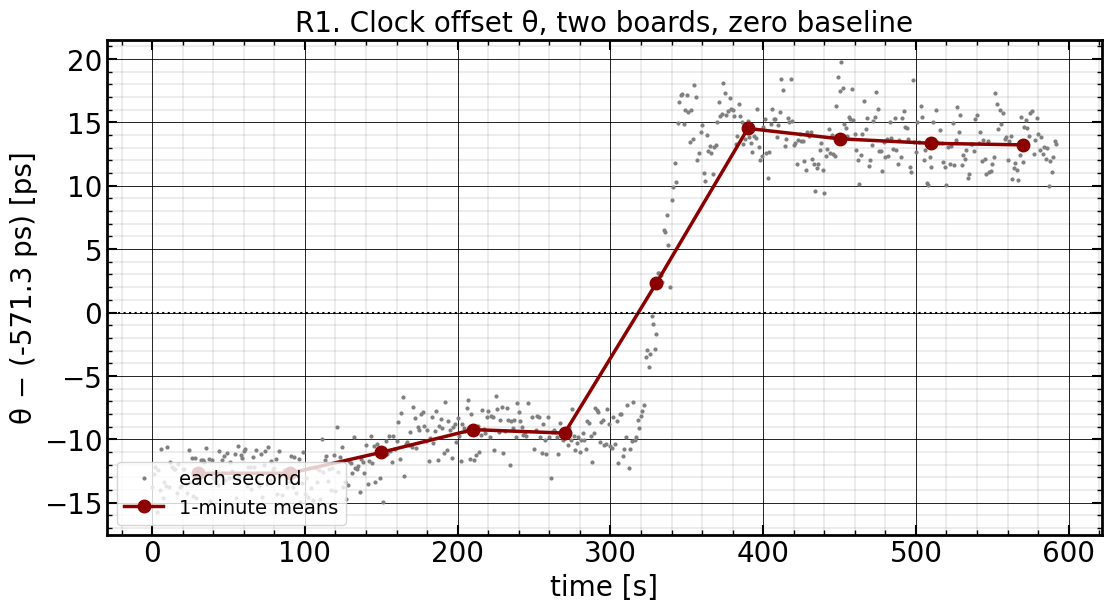

In [26]:
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=200)
    fig.savefig(FIG / f"{name}.pdf")

fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
ax.plot(t, th_ps - th_mean, ".", ms=4, color="grey", label="each second")
mk = np.array([k + 30 for k, _ in minute]); mv = np.array([m for _, m in minute])
ax.plot(mk, mv, "o-", color="darkred", ms=9, lw=2.5, label="1-minute means")
ax.axhline(0, color="k", ls=":", lw=1.5)
ax.set_xlabel("time [s]"); ax.set_ylabel(f"θ − ({th_mean:+.1f} ps) [ps]")
ax.set_title("R1. Clock offset θ, two boards, zero baseline", fontsize=20)
ax.legend(fontsize=14, loc="lower left"); grids(ax)
save(fig, "report_R1_theta"); plt.show()

In [27]:
display(Markdown(f"**Figure R1.** Clock offset θ = (m_AB − m_BA)/2 between the two boards, both on one FS725 (true offset 0), relative to its mean ({th_mean:+.1f} ps, the zero-baseline constant). Grey: every second; red: 1-minute means. Standard deviation {th_sd:.2f} ps over the run; the 1-minute means stay within {key['theta_minute_means_range_ps']:.1f} ps."))

**Figure R1.** Clock offset θ = (m_AB − m_BA)/2 between the two boards, both on one FS725 (true offset 0), relative to its mean (-571.3 ps, the zero-baseline constant). Grey: every second; red: 1-minute means. Standard deviation 12.26 ps over the run; the 1-minute means stay within 27.2 ps.

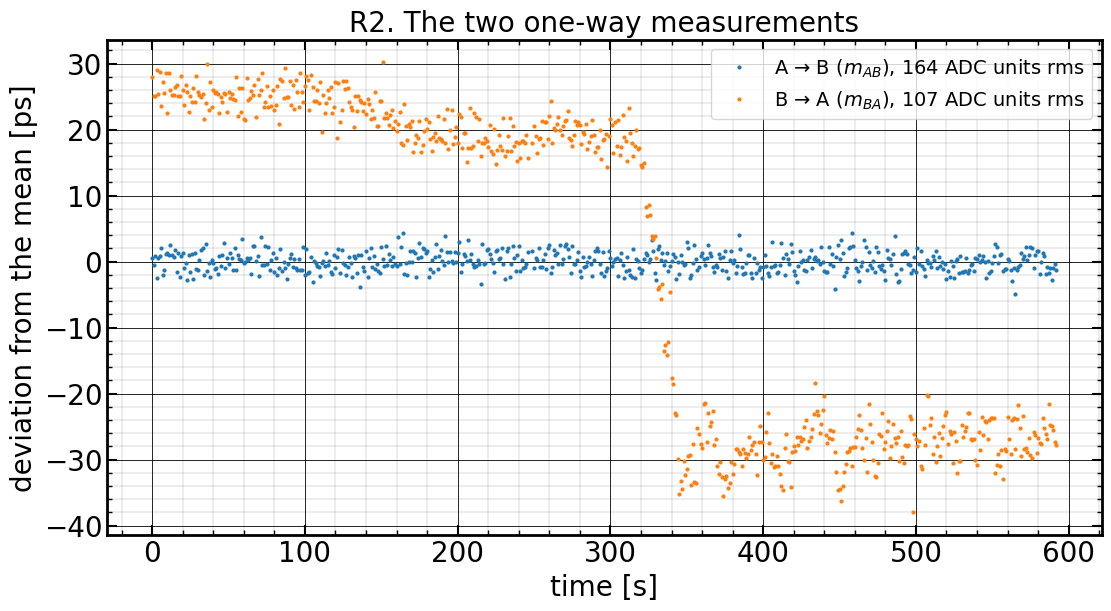

In [28]:
fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
ax.plot(t, (m_ab - m_ab.mean()) * 1e3, ".", ms=4, color="tab:blue", label=f"A → B ($m_{{AB}}$), {lvl_ab:.0f} ADC units rms")
ax.plot(t, (m_ba - m_ba.mean()) * 1e3, ".", ms=4, color="tab:orange", label=f"B → A ($m_{{BA}}$), {lvl_ba:.0f} ADC units rms")
ax.set_xlabel("time [s]"); ax.set_ylabel("deviation from the mean [ps]")
ax.set_title("R2. The two one-way measurements", fontsize=20)
ax.legend(fontsize=14, loc="upper right"); grids(ax)
save(fig, "report_R2_one_way"); plt.show()

In [29]:
display(Markdown(f"**Figure R2.** One-way measurements, each relative to its mean. A → B: {m_ab.std(ddof=1) * 1e3:.1f} ps standard deviation; B → A: {m_ba.std(ddof=1) * 1e3:.1f} ps, received {20 * np.log10(lvl_ba / lvl_ab):+.1f} dB relative to A → B (−10.9 dB before the attenuator fix)."))

**Figure R2.** One-way measurements, each relative to its mean. A → B: 1.5 ps standard deviation; B → A: 24.6 ps, received -3.7 dB relative to A → B (−10.9 dB before the attenuator fix).

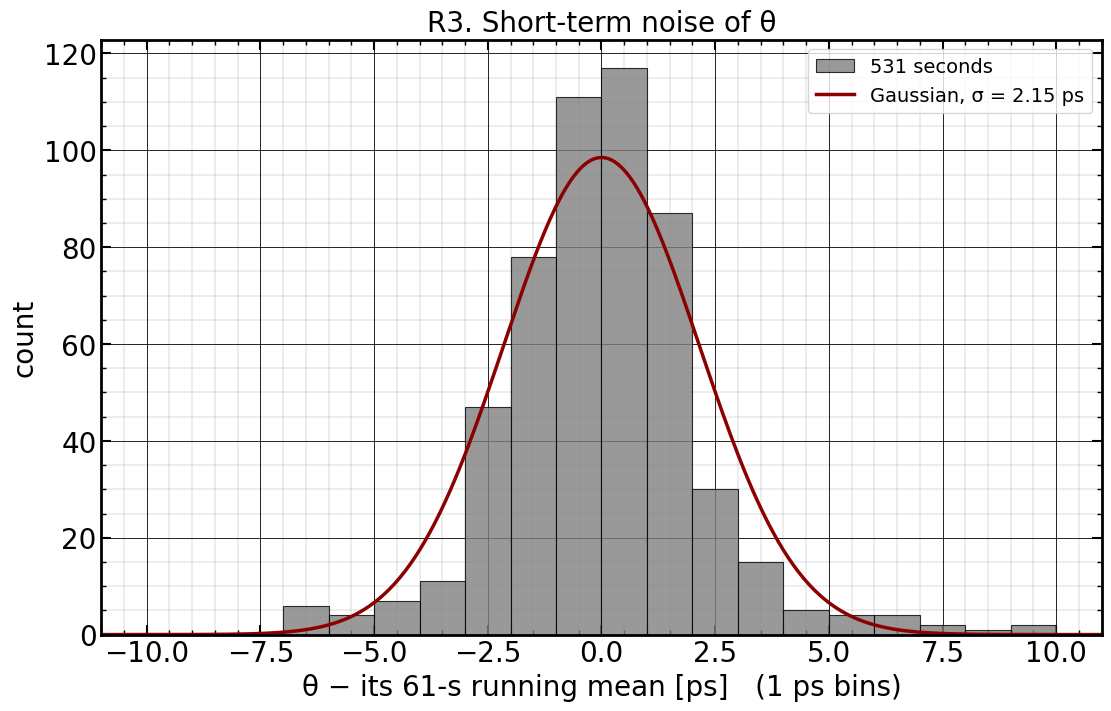

short-term residual sdev 2.15 ps, Shapiro-Wilk p = 0.00


In [30]:
BIN_R = 1.0
edge = BIN_R * np.ceil(np.abs(th_res).max() / BIN_R + 1)
bins = np.arange(-edge, edge + BIN_R / 2, BIN_R)
x = np.linspace(bins[0], bins[-1], 400)
sd_r = th_res.std(ddof=1)
fig, ax = plt.subplots(1, 1, figsize=(11, 7), layout='constrained')
ax.hist(th_res, bins=bins, color="grey", edgecolor="k", lw=0.8, alpha=0.8, label=f"{th_res.size} seconds")
ax.plot(x, th_res.size * BIN_R * stats.norm.pdf(x, 0, sd_r), "-", color="darkred", lw=2.5, label=f"Gaussian, σ = {sd_r:.2f} ps")
ax.set_xlim(bins[0], bins[-1])
ax.set_xlabel(f"θ − its {res_win}-s running mean [ps]   ({BIN_R:.0f} ps bins)"); ax.set_ylabel("count")
ax.set_title("R3. Short-term noise of θ", fontsize=20)
ax.legend(fontsize=14, loc="upper right"); grids(ax)
save(fig, "report_R3_theta_noise"); plt.show()
print(f"short-term residual sdev {sd_r:.2f} ps, Shapiro-Wilk p = {stats.shapiro(th_res).pvalue:.2f}")

In [31]:
display(Markdown(f"**Figure R3.** Short-term noise of θ: each second minus the centred 61-s running mean, which removes slow wander. Gaussian, {sd_r:.2f} ps standard deviation: the precision of a single 1-second measurement with the present signal levels ({resid(th_p).std(ddof=1):.2f} ps before the fix)."))

**Figure R3.** Short-term noise of θ: each second minus the centred 61-s running mean, which removes slow wander. Gaussian, 2.15 ps standard deviation: the precision of a single 1-second measurement with the present signal levels (3.25 ps before the fix).

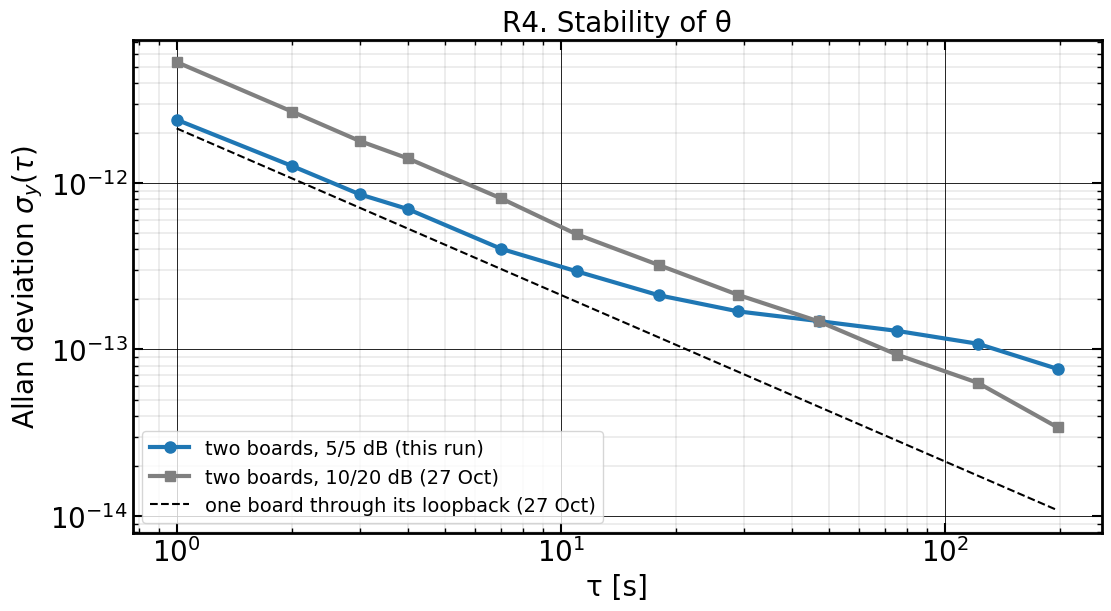

In [32]:
fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
ax.loglog(taus, ad, "o-", color="tab:blue", ms=8, label="two boards, 5/5 dB (this run)")
ax.loglog(tausP, adP, "s-", color="grey", ms=7, label="two boards, 10/20 dB (27 Oct)")
ax.loglog(taus, 2.13e-12 / taus, "k--", lw=1.5, label="one board through its loopback (27 Oct)")
ax.set_xlabel("τ [s]"); ax.set_ylabel("Allan deviation $\\sigma_y(\\tau)$")
ax.set_title("R4. Stability of θ", fontsize=20)
ax.legend(fontsize=14, loc="lower left"); grids(ax)
save(fig, "report_R4_allan"); plt.show()

In [33]:
display(Markdown(f"**Figure R4.** Overlapping Allan deviation of θ. At 1 s it is {ad[0]:.1e}, close to the one-board self-test (dashed, {2.13e-12:.1e}) and half of the run before the attenuator fix (grey, {adP[0]:.1e}). It falls as 1/τ (white time noise) up to about 20 s ({ad[list(taus).index(18)]:.1e} at 18 s), then flattens ({ad[list(taus).index(122)]:.1e} at 122 s, {ad[-1]:.1e} at {taus[-1]} s): there the B → A drift and step (Figure R2) dominate. Beyond about 30 s the run before the fix is no worse ({adP[list(tausP).index(122)]:.1e} at 122 s), so the fix improved the short-term noise but not the long-term stability."))

**Figure R4.** Overlapping Allan deviation of θ. At 1 s it is 2.4e-12, close to the one-board self-test (dashed, 2.1e-12) and half of the run before the attenuator fix (grey, 5.3e-12). It falls as 1/τ (white time noise) up to about 20 s (2.1e-13 at 18 s), then flattens (1.1e-13 at 122 s, 7.6e-14 at 197 s): there the B → A drift and step (Figure R2) dominate. Beyond about 30 s the run before the fix is no worse (6.3e-14 at 122 s), so the fix improved the short-term noise but not the long-term stability.

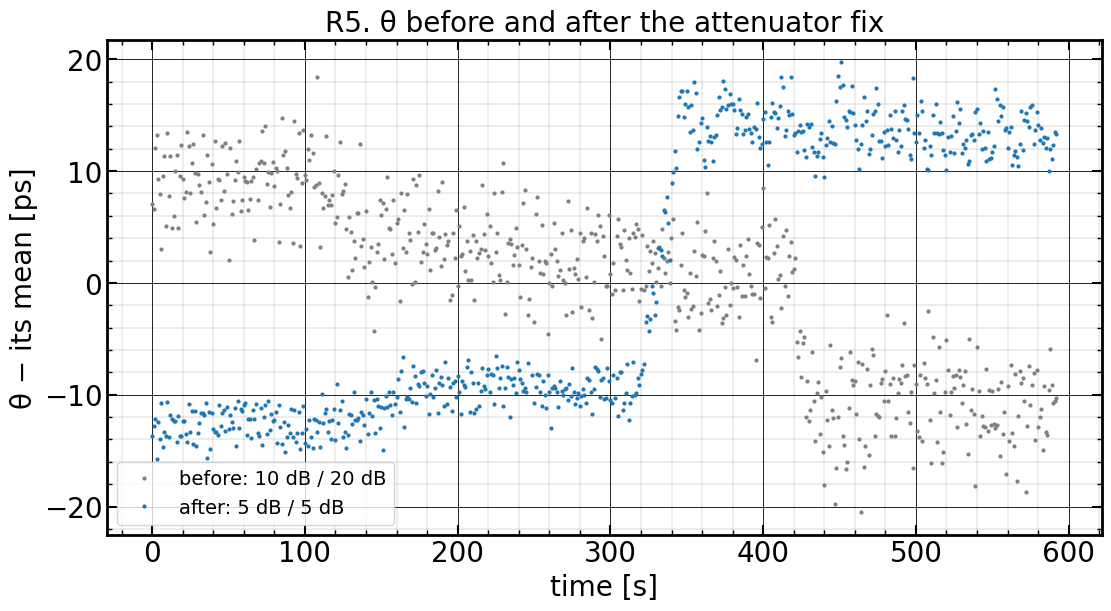

In [34]:
fig, ax = plt.subplots(1, 1, figsize=(11, 6), layout='constrained')
ax.plot(tP, th_p - th_p.mean(), ".", ms=4, color="grey", label="before: 10 dB / 20 dB")
ax.plot(t, th_ps - th_mean, ".", ms=4, color="tab:blue", label="after: 5 dB / 5 dB")
ax.set_xlabel("time [s]"); ax.set_ylabel("θ − its mean [ps]")
ax.set_title("R5. θ before and after the attenuator fix", fontsize=20)
ax.legend(fontsize=14, loc="lower left"); grids(ax)
save(fig, "report_R5_before_after"); plt.show()

In [35]:
display(Markdown(f"**Figure R5.** θ relative to its mean, same two boards and set-up, before (grey: A → B 10 dB, B → A 20 dB) and after (blue: 5 dB both) matching the attenuators. Standard deviation {th_p.std(ddof=1):.1f} ps before, {th_sd:.1f} ps after; per-second noise {s2s(th_p):.2f} ps before, {s2s(th_ps):.2f} ps after. The constant changed from {th_p.mean():+.1f} ps to {th_mean:+.1f} ps because the attenuators are part of the two paths."))

**Figure R5.** θ relative to its mean, same two boards and set-up, before (grey: A → B 10 dB, B → A 20 dB) and after (blue: 5 dB both) matching the attenuators. Standard deviation 8.0 ps before, 12.3 ps after; per-second noise 3.09 ps before, 1.42 ps after. The constant changed from -647.2 ps to -571.3 ps because the attenuators are part of the two paths.